# RTENSO2026 El Nino cases: Nino-index forecast plumes

Case-study companion to ESP-Lab `3a_sst_skill_ts.ipynb`. Instead of skill over many
start years, this notebook follows single events (`EVENTS`): the 2015/16 El Nino from the 2015
Feb/May/Aug/Nov starts and the 2026/27 El Nino from the 2026 Feb/May/Aug starts of RTENSO2026 (`clim` and `obs` land/sea-ice/river ICs) and the
Reanalysis (BruteForce) hindcasts (2015 only), against HadISST 1.1, ERSSTv5, ESA CCI SST v3.0 and NOAA OISST v2.1.

Model anomalies remove a lead-time climatology from the Reanalysis (BruteForce) 1981-2010
hindcasts (drift correction, `CLIM_METHOD = "start_drift"`; see `matched_climatology` in
`util/rtenso_case.py` and the README): the observed 1981-2010 climatology of the target month plus
the model drift at the same lead, averaged over every Reanalysis start of the same month in
1981-2010 (30 years for May and Nov, which equals their Reanalysis climatology; 1985, 1990, ...,
2010 for Feb and Aug). `"lead_drift"`, `"direct"` and `"target_month"` remain for sensitivity tests. Each observed
product's anomalies are relative to its own 1981-2010 monthly climatology; HadISST 1.1
is the reference for errors and the peak-season summary. ERA5-Land has no ocean
points, so it gives no Nino index. Indices use
`TS` box means (all-ocean boxes), as in 3a. The RONI outlook at the end follows NOAA CPC's Relative
Oceanic Niño Index (operational since Feb 2026): the 3-month running mean of the Niño3.4 anomaly minus
the 20°S-20°N tropical-mean SST anomaly, rescaled to the ONI's standard deviation.

**1 Feb 2026 start:** `Reanalysis-CLIM` and `Reanalysis-OBS` started from the same BruteForce 2010 land/river/sea-ice state and are bit-identical, so their curves/maps coincide (see "1 Feb 2026 start" in `README.md`).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from datetime import datetime

from IPython.display import display

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from matplotlib.colors import BoundaryNorm
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

import sys
from pathlib import Path
# diagnostic/ (the shared util package) is the first parent folder holding util/rtenso_case.py
DIAG_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "util" / "rtenso_case.py").is_file())
sys.path.insert(0, str(DIAG_ROOT))
from util import rtenso_case as rc

def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]

### Run controls

In [2]:
NOTEBOOK = "enso/01_enso_plume"   # outputs: rc.OUTPUT_ROOT/enso/01_enso_plume/{figures,data}/
FORCE_COMPUTE = False   # False: read valid caches, build missing or stale ones; True: recompute this notebook's products
                        # (shared Reanalysis/observation/ERA5 caches are reused; set rc.REBUILD_REFERENCE = True to redo them)
derivation_mode = "rebuild" if FORCE_COMPUTE else "auto"
# Drift correction: "start_drift" (default; obs target-month climatology + drift of the Reanalysis starts of the same month),
# or "lead_drift", "direct", "target_month" for sensitivity tests (see the README)
CLIM_METHOD = "start_drift"

INDICES = ["Nino3.4", "ONI", "Nino3", "Nino4", "Nino12"]   # ONI: 3-month running mean of Nino3.4
TROPICAL_BOX = (0.0, 360.0, -20.0, 20.0)   # RONI tropical mean: ocean points 20S-20N (lon0, lon1, lat0, lat1)
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}

# Observed SST products (rc.OBS_ALT_PRODUCTS); OBS_REFERENCE is used for errors and the summary
OBS_REFERENCE = "HadISST1.1"
OBS_PRODUCTS = {
    "HadISST1.1": {"color": "k", "ls": "-"},
    "ERSSTv5": {"color": "0.4", "ls": "--"},
    "ESA_CCI_SST": {"color": "k", "ls": ":"},
    "OISSTv2.1": {"color": "0.4", "ls": "-."},   # NOAA OISST v2.1 (1981-09 on; Jan-Aug climatology 1982-2010)
}

# Events and hindcast cases: the shared registry in util/rtenso_case.py (rc.EVENTS, rc.CASES). A case is
# used only for the starts it has (rc.has_start: Reanalysis-FOSIRL has no 2026 run).
EVENTS = rc.EVENTS
CASES = rc.CASES

OUTDIR = rc.output_dir(NOTEBOOK, "data")
OUTDIR.mkdir(parents=True, exist_ok=True)
print("figures ->", rc.figure_dir(NOTEBOOK))

figures -> /global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures


### Observed and forecast Nino indices

In [3]:
%%time
obs_indices = {}  # (year, product) -> Dataset of (time) index anomalies
fc_index = {}     # (year, case, init) -> Dataset of (member, lead) index anomalies
ocean = rc.land_fraction() < 0.5   # the observed SST mask, applied to the model TS (land skin temperature) too
for year, event in EVENTS.items():
    season = event["peak_season"]
    for product in OBS_PRODUCTS:
        obs_ts = rc.obs_anomaly("TS", years=(year, year + 2), mode=derivation_mode, product=product)
        obs_indices[(year, product)] = rc.nino_indices(obs_ts, INDICES).load()
        obs_indices[(year, product)]["TropicalMean"] = rc.box_mean(obs_ts, TROPICAL_BOX).load()   # RONI
        nino = obs_indices[(year, product)]["Nino3.4"].dropna("time")
        last = nino["time"].values[-1]
        print(f"[{year} {product}] observed through {last.year}-{last.month:02d}; Nino3.4 {season['label']} = "
              f"{float(rc.obs_target_mean(nino, season['months'])):.2f} C")

    for case in CASES:
        for init in event["init_months"]:
            if not rc.has_start(case, year, init):
                continue
            anom = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, "TS", year=year,
                                       method=CLIM_METHOD, mode=derivation_mode)
            if anom is None:
                print(f"[{year} {case} init{init:02d}] not available")
                continue
            ds = rc.nino_indices(anom, INDICES)
            ds["TropicalMean"] = rc.box_mean(anom.where(ocean), TROPICAL_BOX)   # RONI
            ds.attrs.update(case=case, init_year=year, init_month=init, climatology_method=anom.attrs["climatology_method"])
            fc_index[(year, case, init)] = ds.load()
            source = CASES[case]["source"]
            atomic_to_netcdf(ds.drop_vars("time"), OUTDIR / f"{source}_init{init:02d}_TS_y{year}_N{ds.sizes['member']}_M{ds.sizes['lead']}_NinoSST_mon.nc")
            print(f"[{year} {case} init{init:02d}] {ds.sizes['member']} members, Nino3.4 lead 0 = {float(ds['Nino3.4'].isel(lead=0).mean()):.2f} C")

[2015 HadISST1.1] observed through 2017-12; Nino3.4 DJF 2015/16 = 2.42 C
[2015 ERSSTv5] observed through 2017-12; Nino3.4 DJF 2015/16 = 2.48 C
[2015 ESA_CCI_SST] observed through 2017-12; Nino3.4 DJF 2015/16 = 2.69 C


[2015 OISSTv2.1] observed through 2017-12; Nino3.4 DJF 2015/16 = 2.49 C


[2015 Reanalysis-CLIM init02] 10 members, Nino3.4 lead 0 = 0.74 C


[2015 Reanalysis-CLIM init05] 10 members, Nino3.4 lead 0 = 1.27 C


[2015 Reanalysis-CLIM init08] 10 members, Nino3.4 lead 0 = 2.11 C


[2015 Reanalysis-CLIM init11] 10 members, Nino3.4 lead 0 = 2.76 C


... (21 outputs left out)

[2026 Reanalysis-NSIDC init02] 10 members, Nino3.4 lead 0 = -0.33 C


[2026 Reanalysis-NSIDC init05] 10 members, Nino3.4 lead 0 = 1.01 C


[2026 Reanalysis-NSIDC init08] 10 members, Nino3.4 lead 0 = 2.92 C


[2026 Reanalysis-NSIDC init11] 10 members, Nino3.4 lead 0 = 3.55 C
CPU times: user 20.7 s, sys: 27.1 s, total: 47.8 s
Wall time: 1min 13s


### Forecast plumes

Thin lines are members, thick lines ensemble means, black/grey lines are the observed products (HadISST 1.1 solid, ERSSTv5 dashed, ESA CCI dotted, NOAA OISST dash-dot). The grey dashed vertical line marks each initialization and the purple shading the observed peak period: contiguous months around the reference-product maximum with anomalies of at least `peak_frac` (90%) of that maximum.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_init11.png


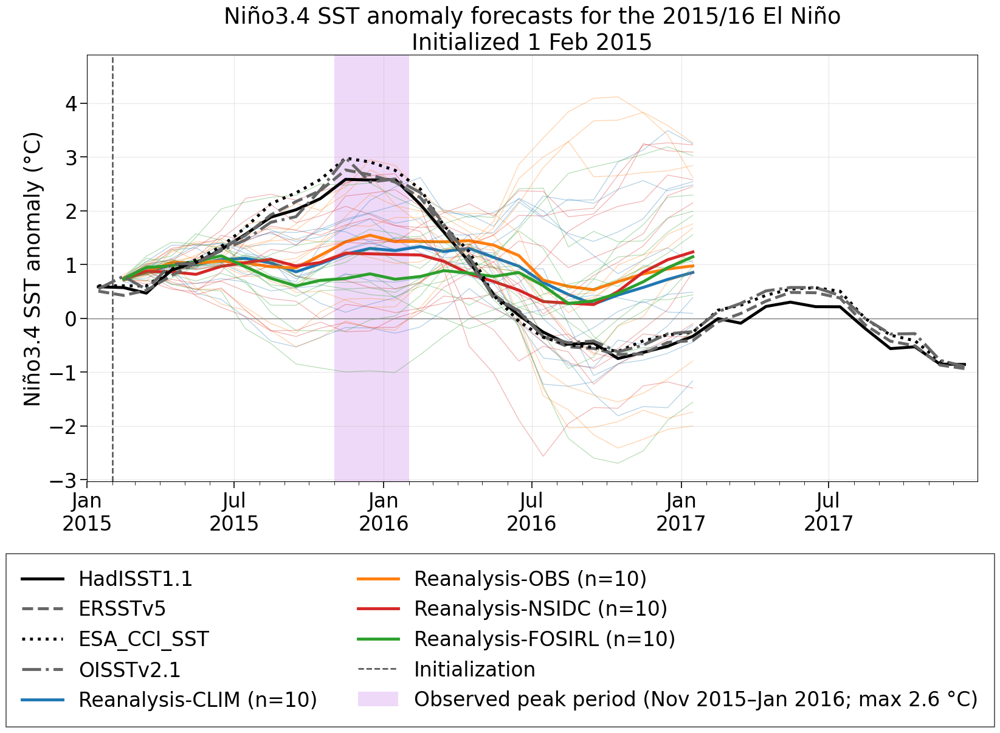

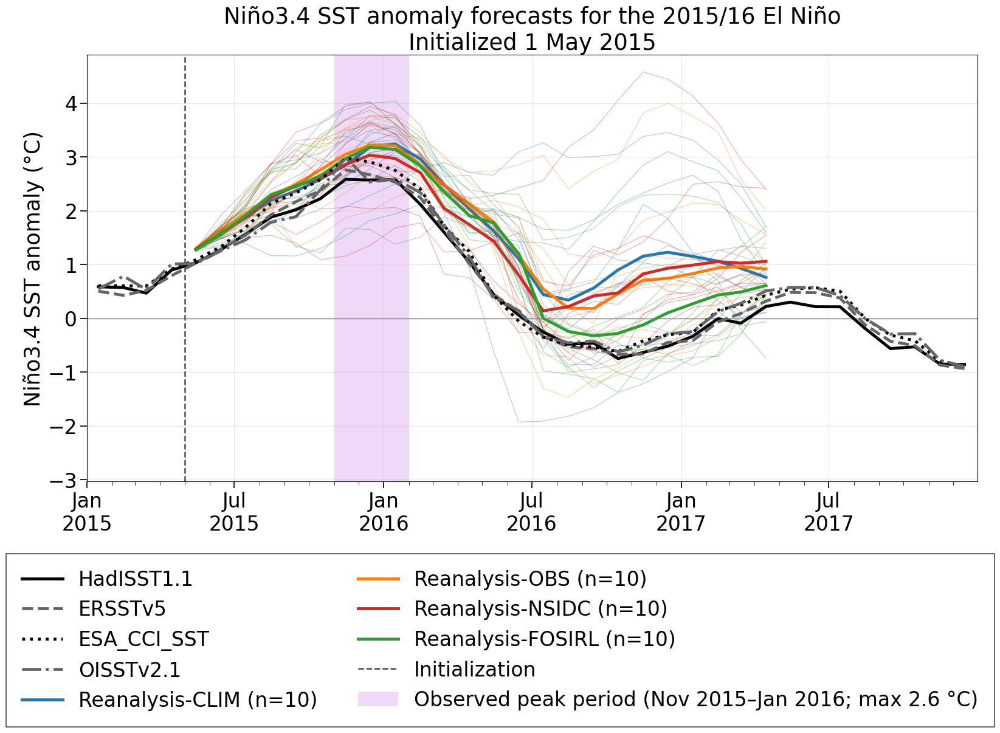

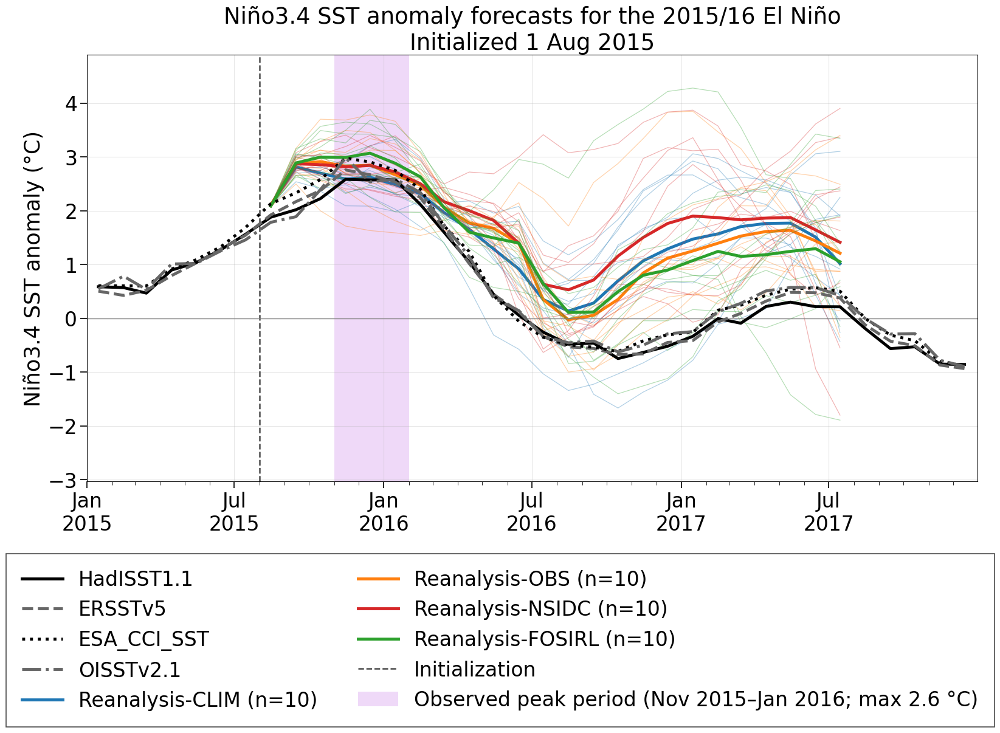

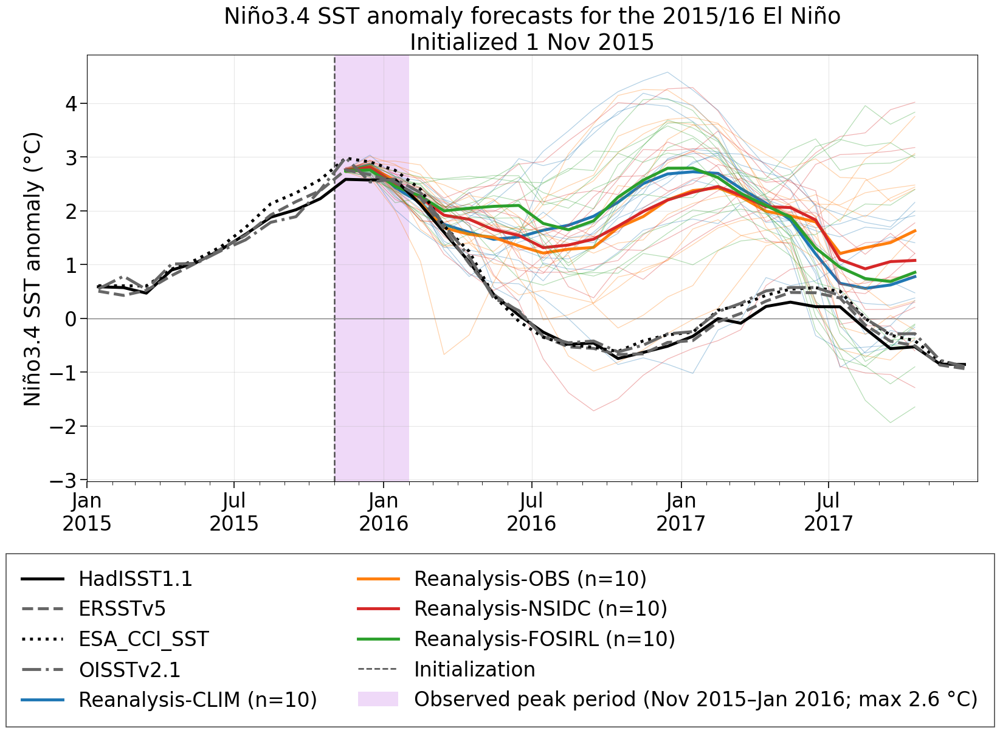

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_oni_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_oni_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_oni_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_oni_init11.png


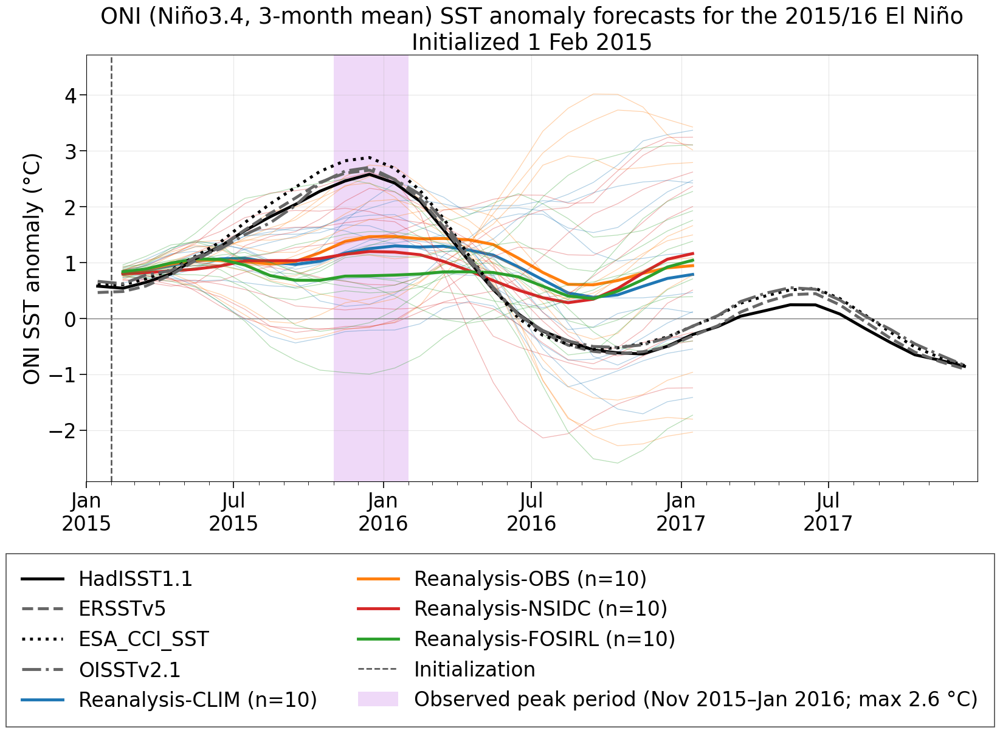

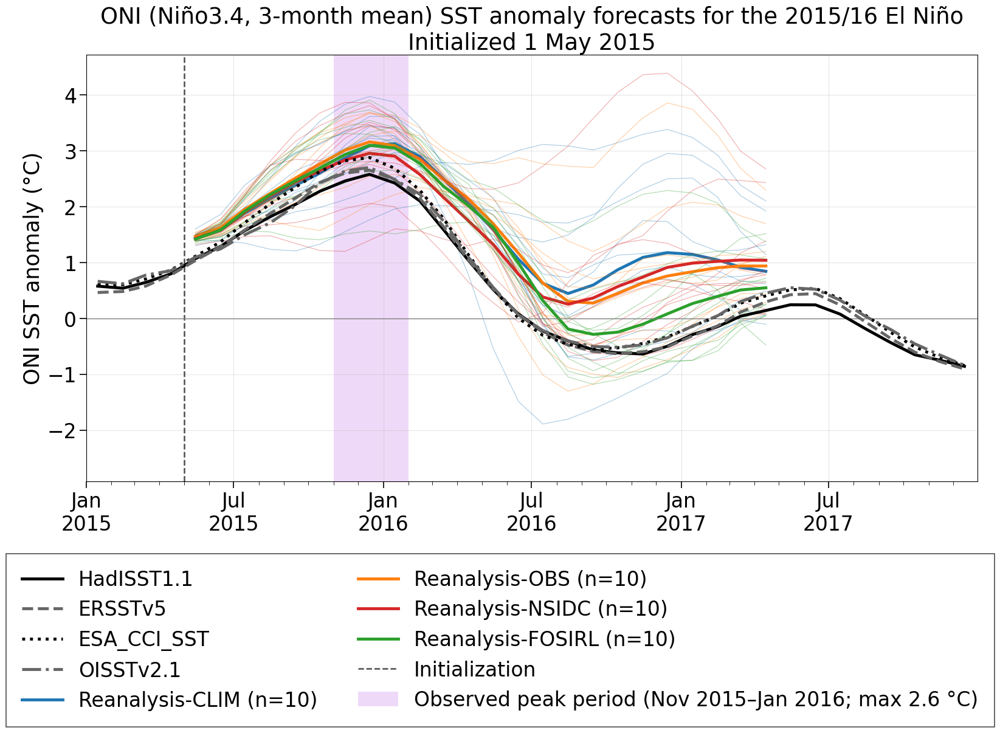

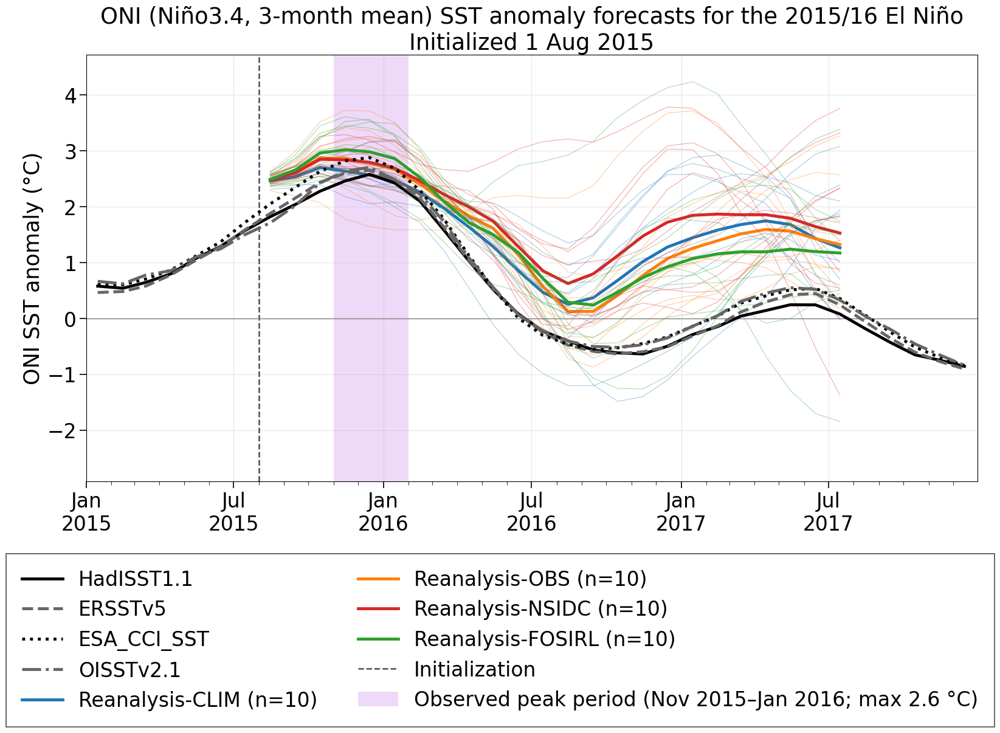

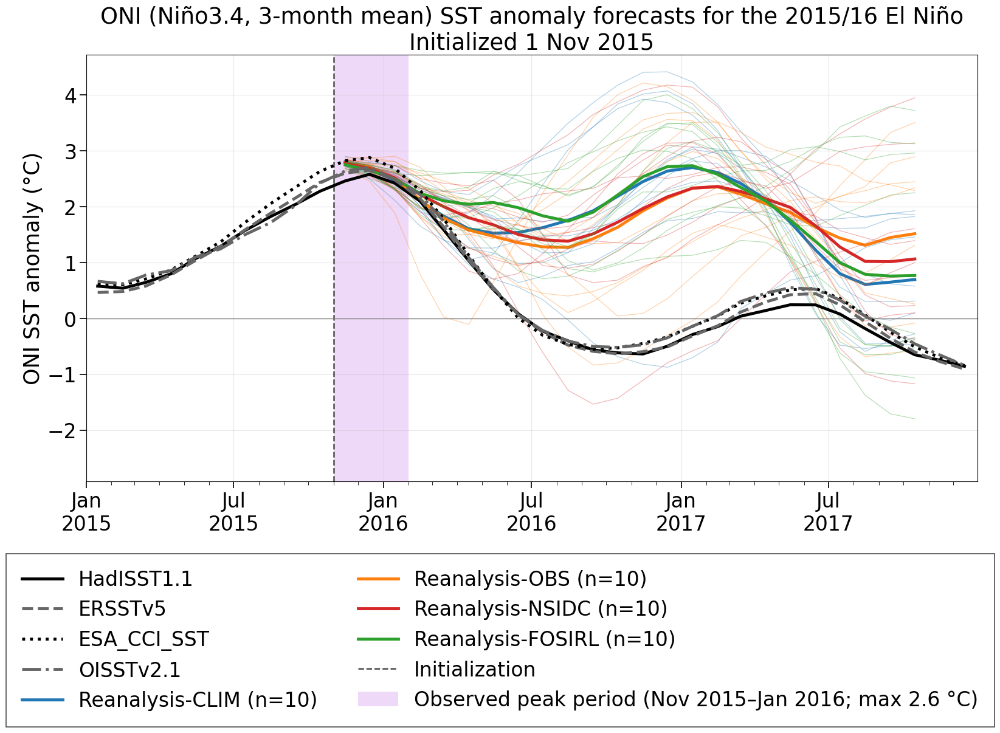

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_init11.png


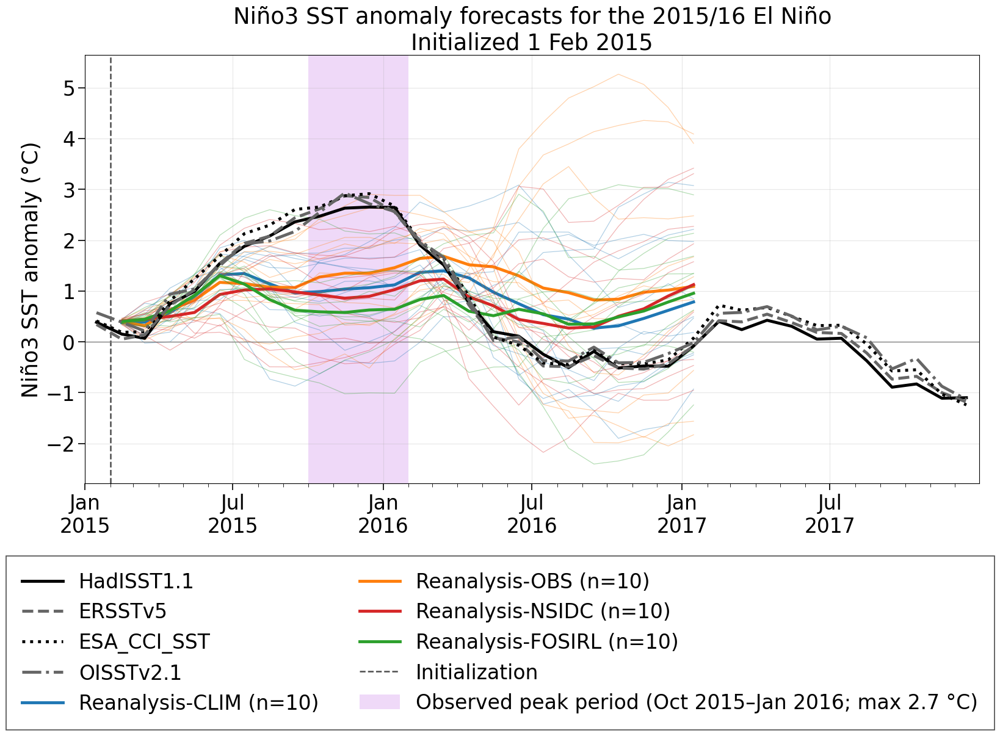

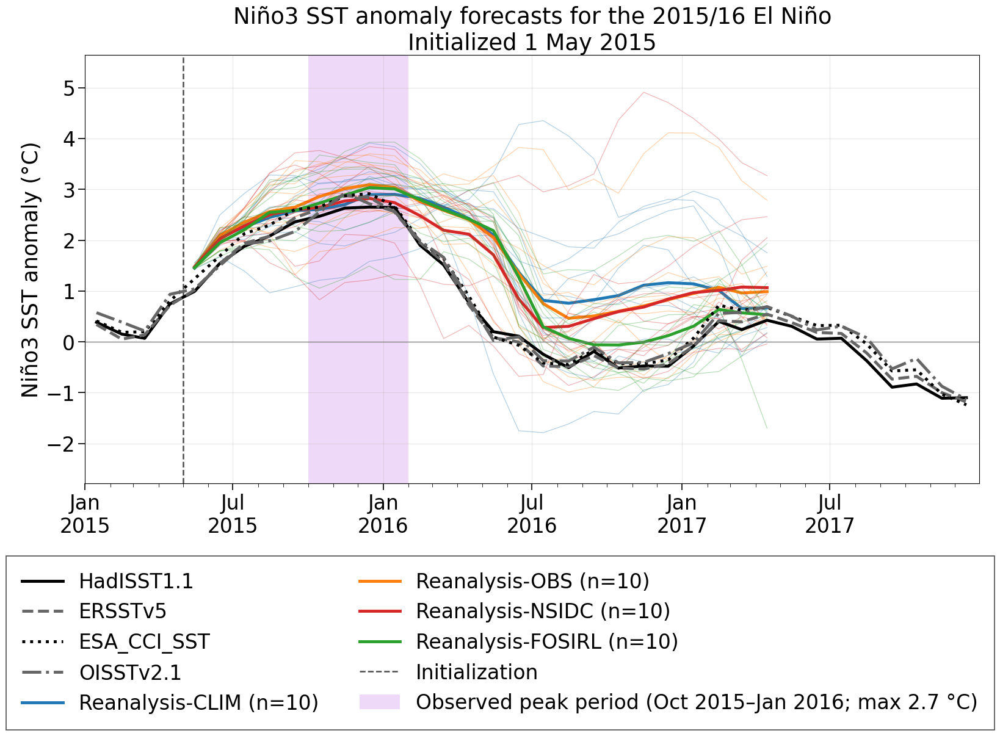

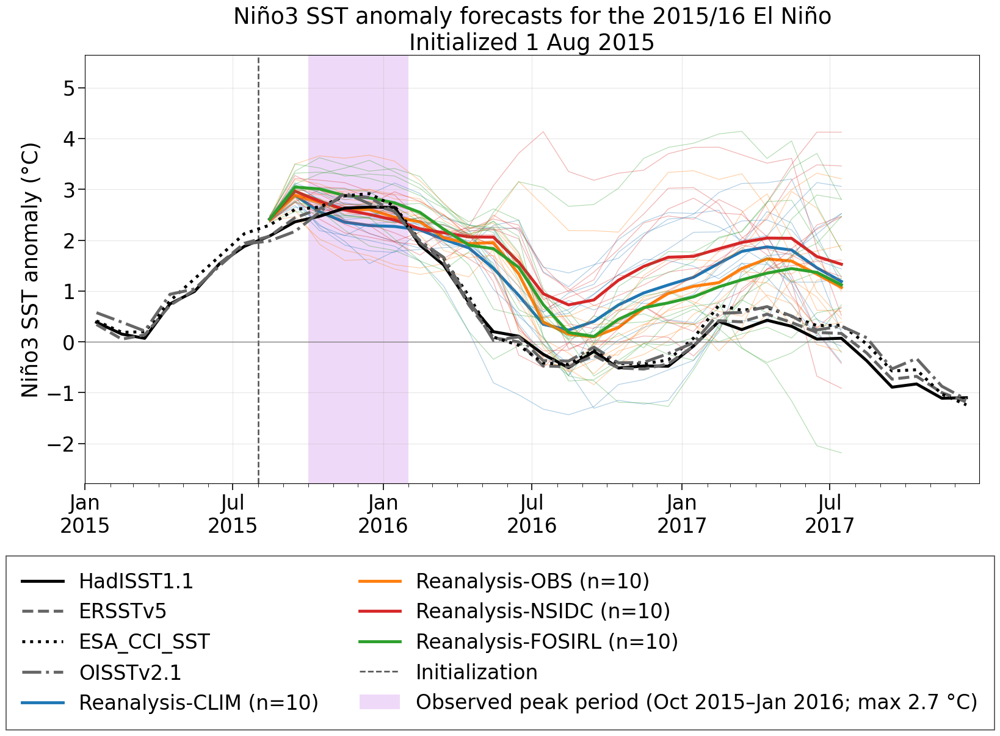

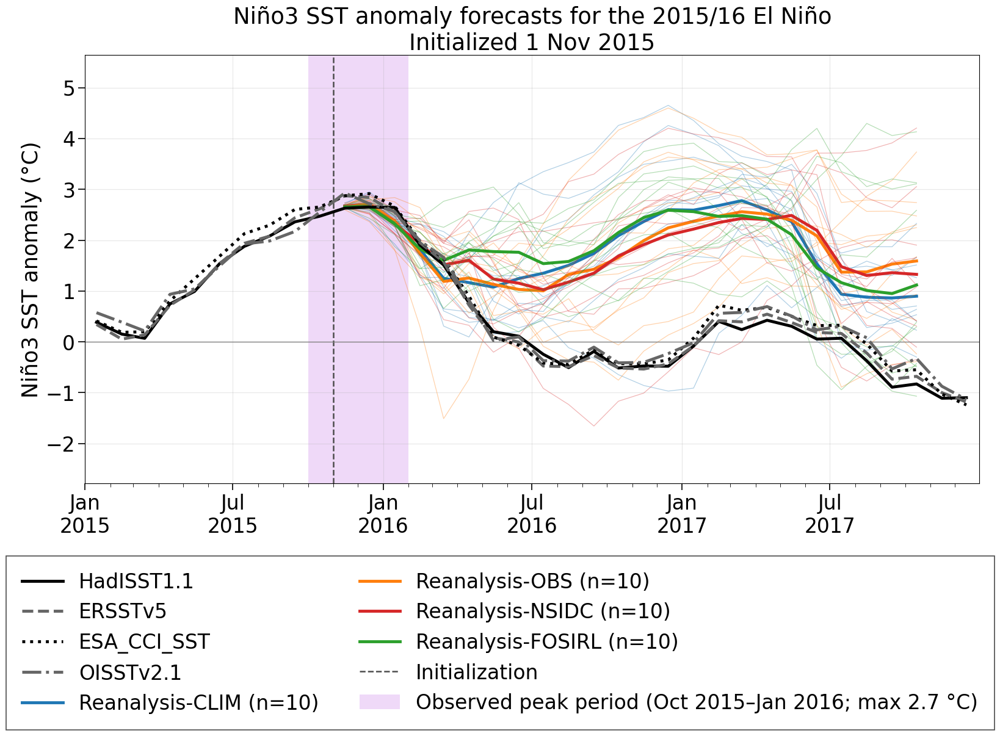

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino4_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino4_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino4_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino4_init11.png


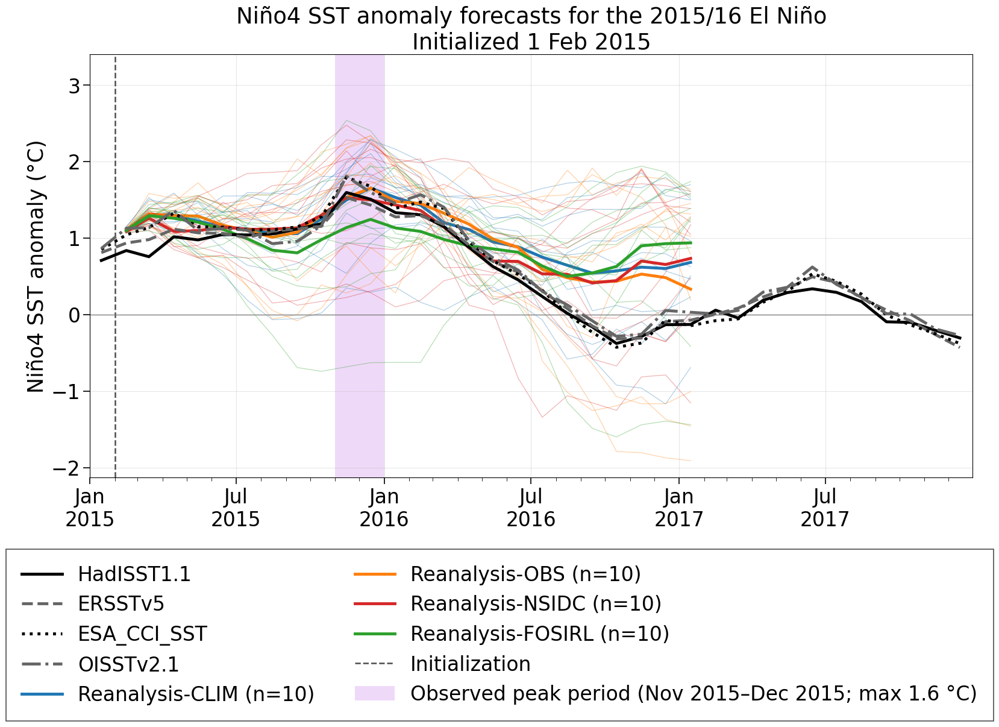

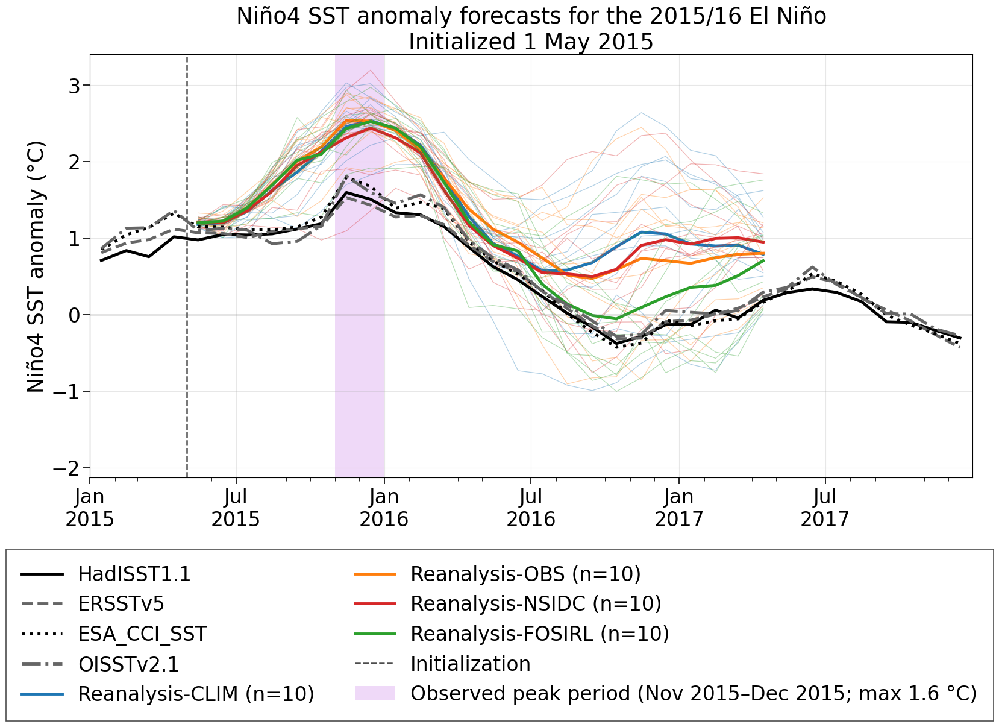

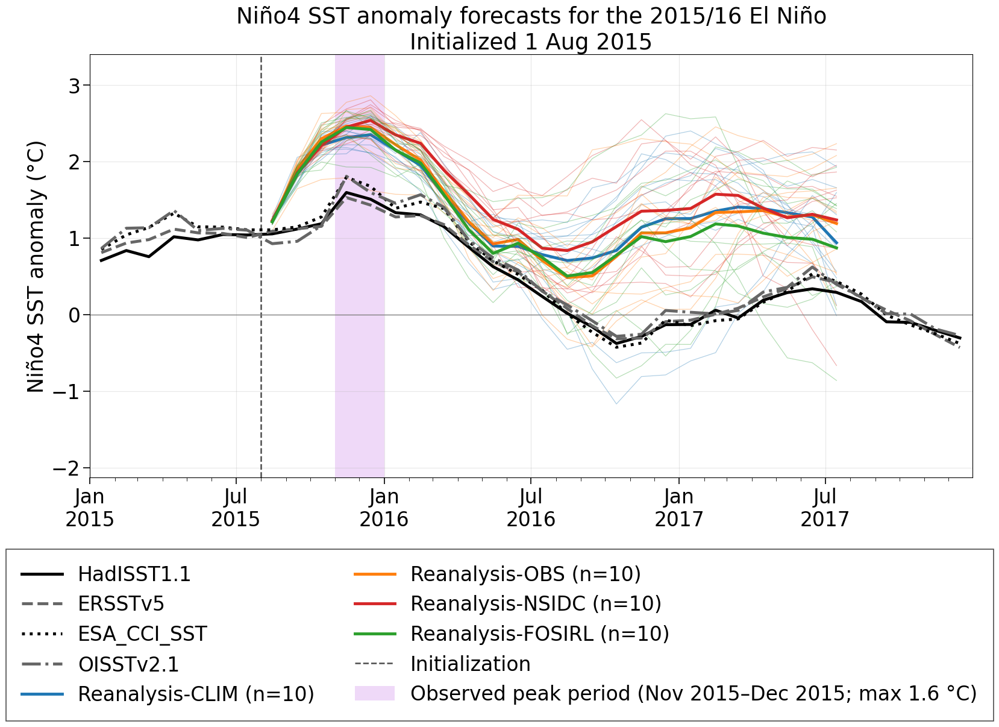

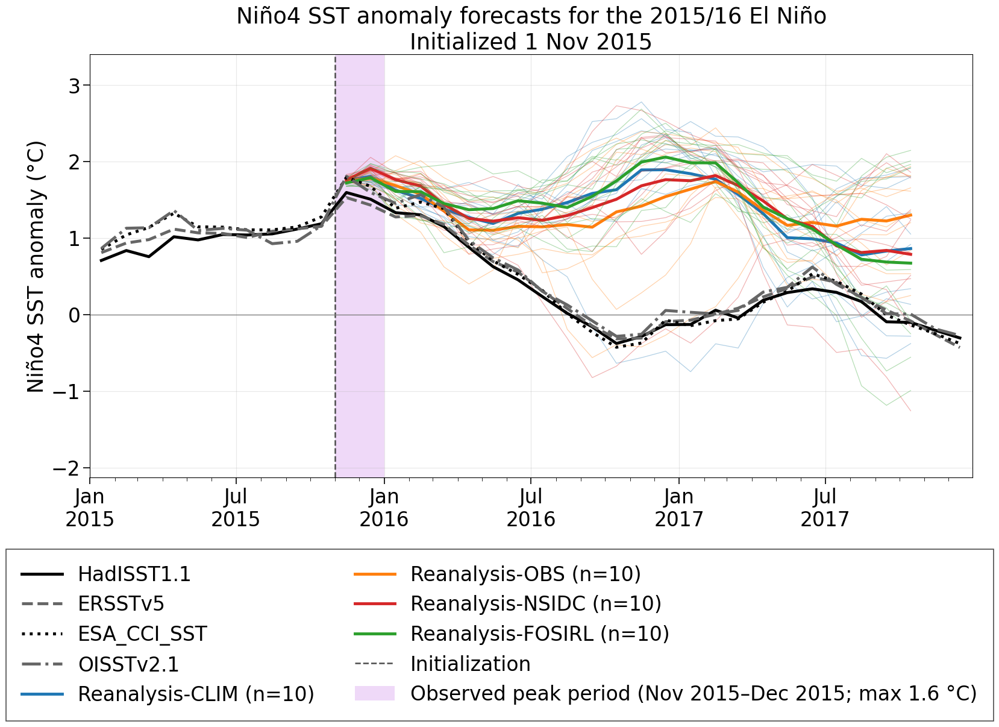

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino12_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino12_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino12_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino12_init11.png


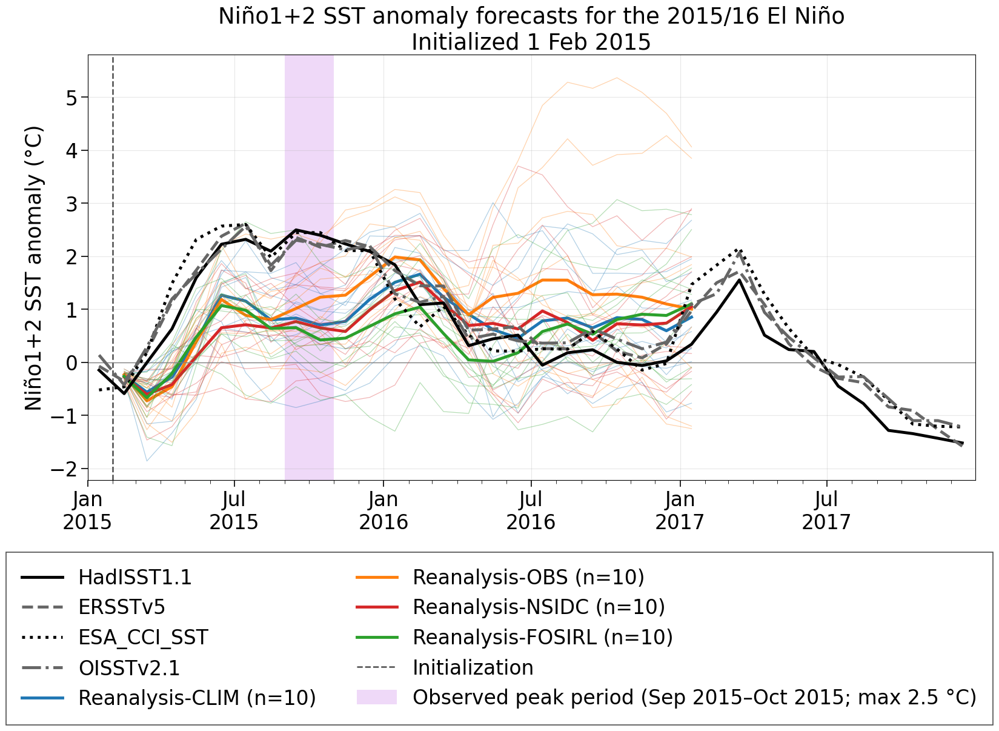

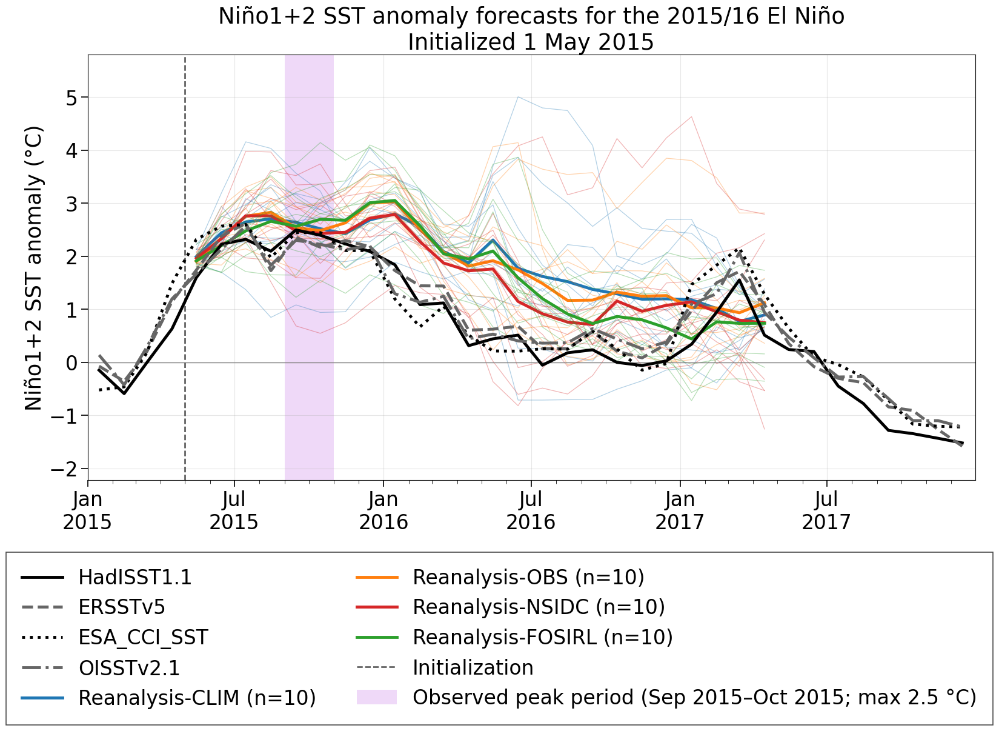

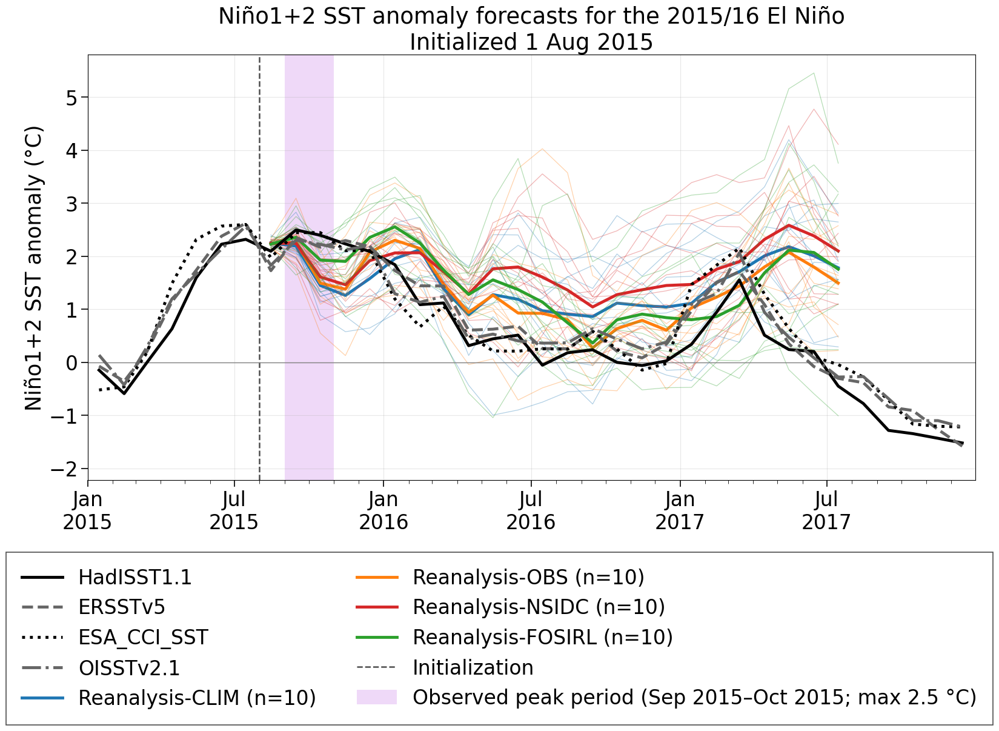

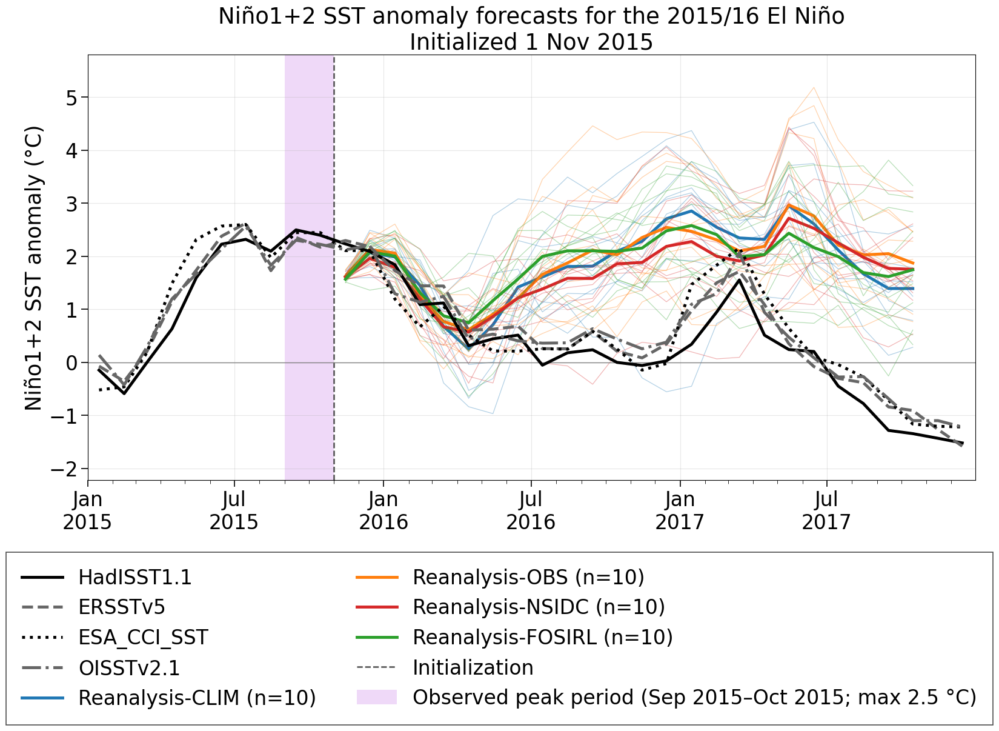

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_init11.png


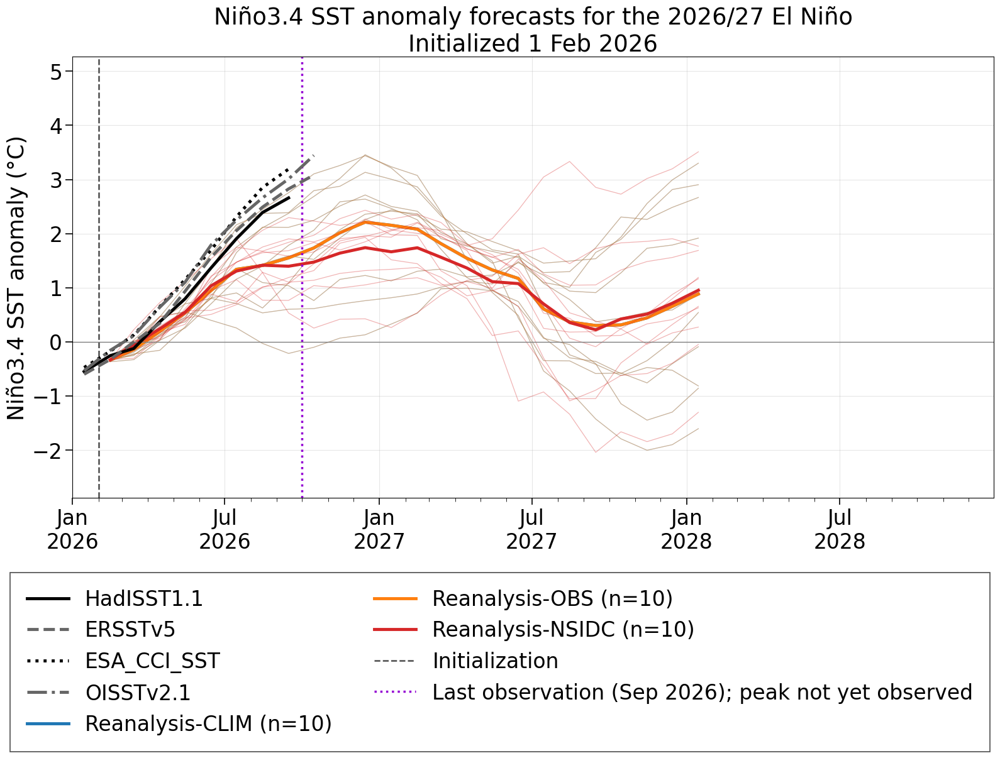

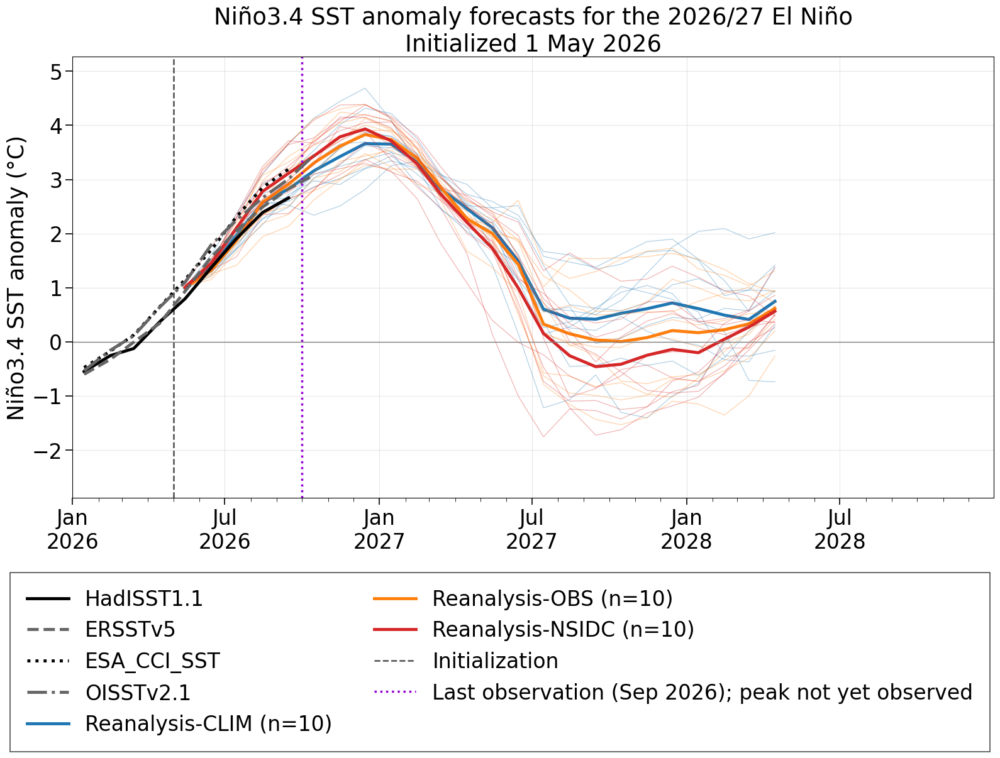

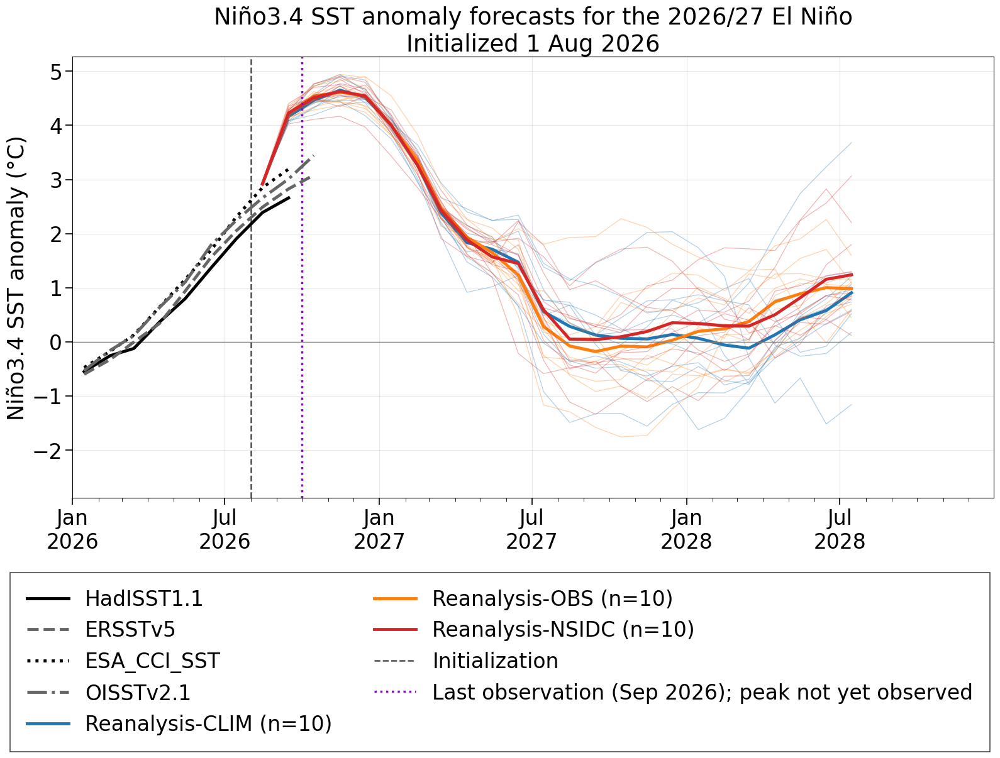

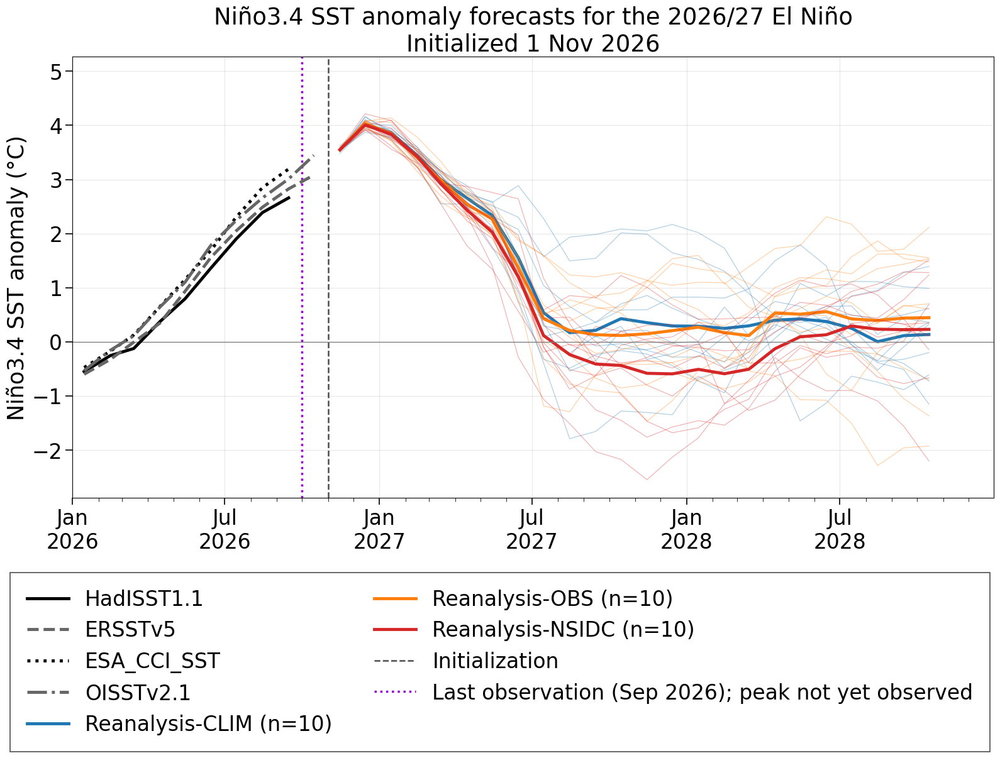

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_oni_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_oni_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_oni_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_oni_init11.png


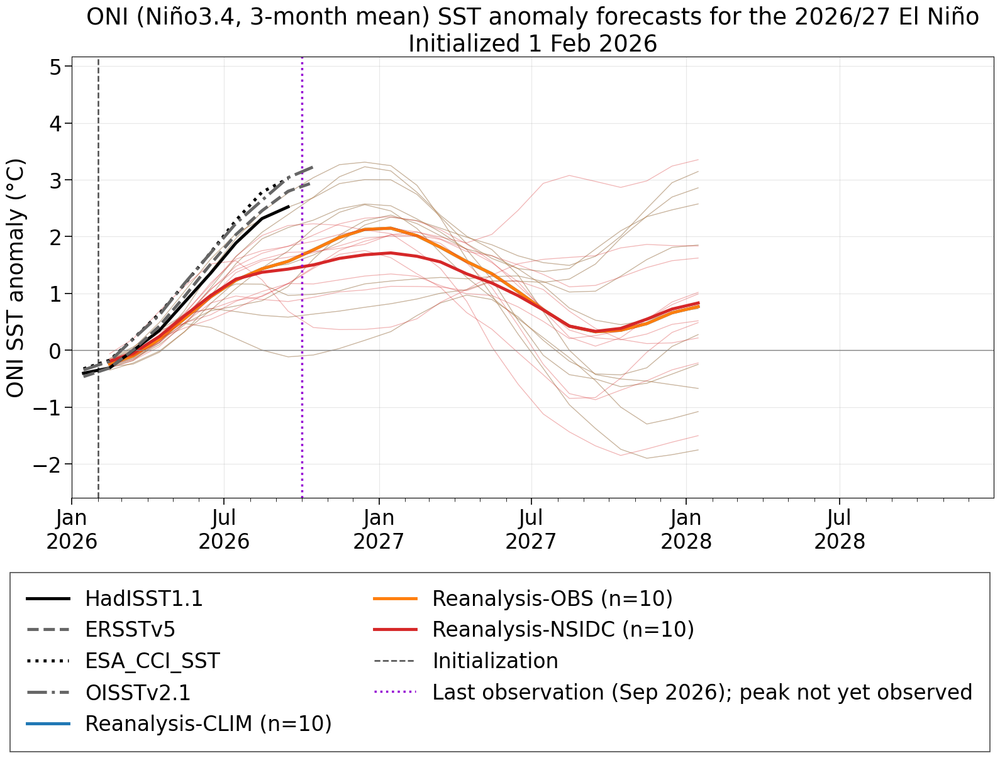

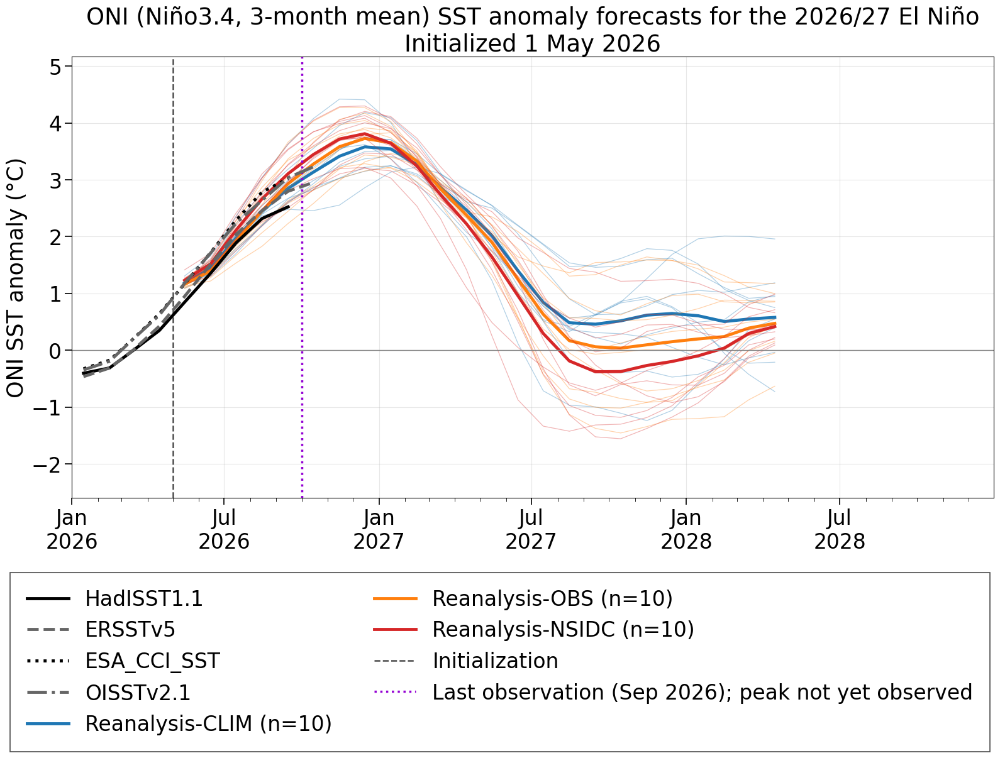

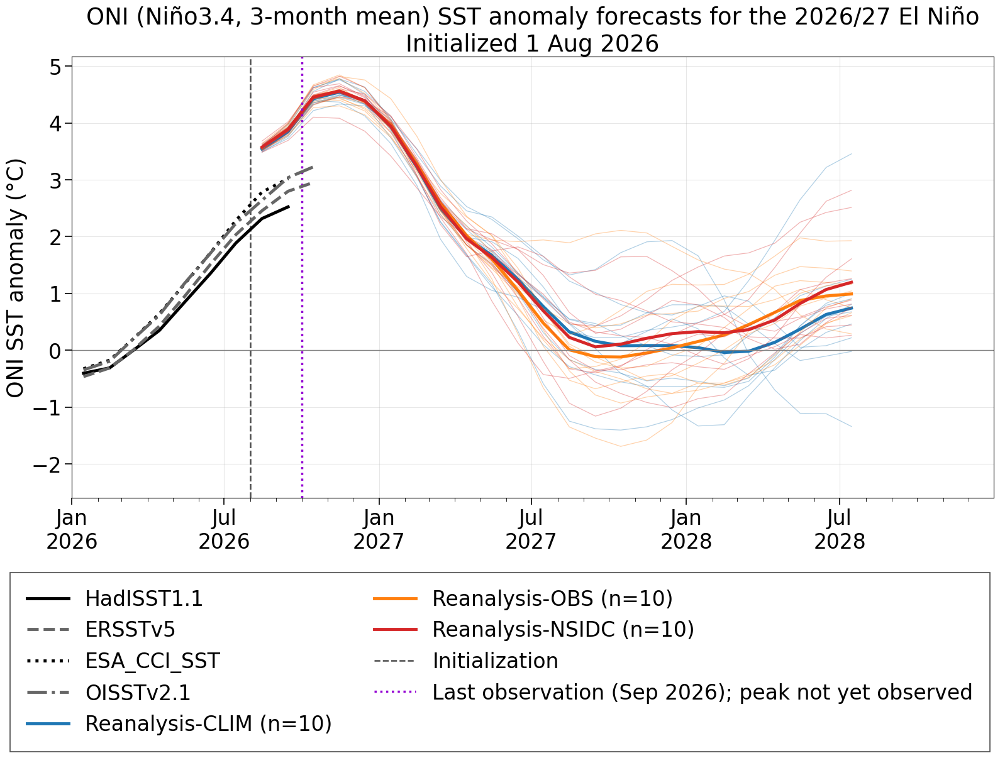

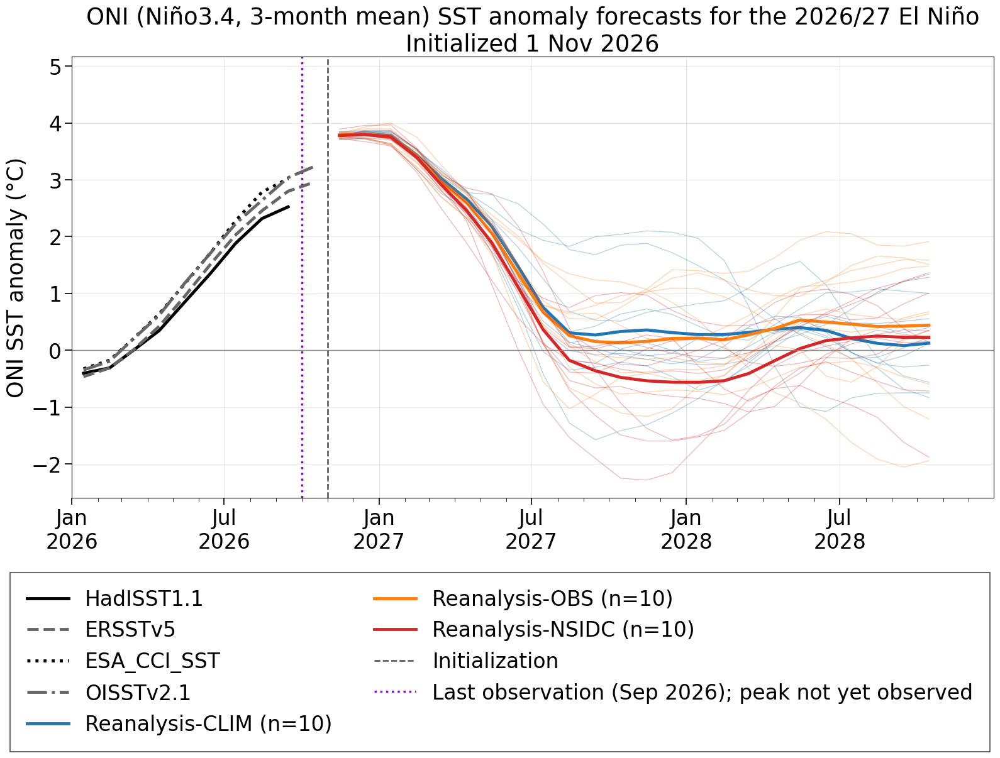

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_init11.png


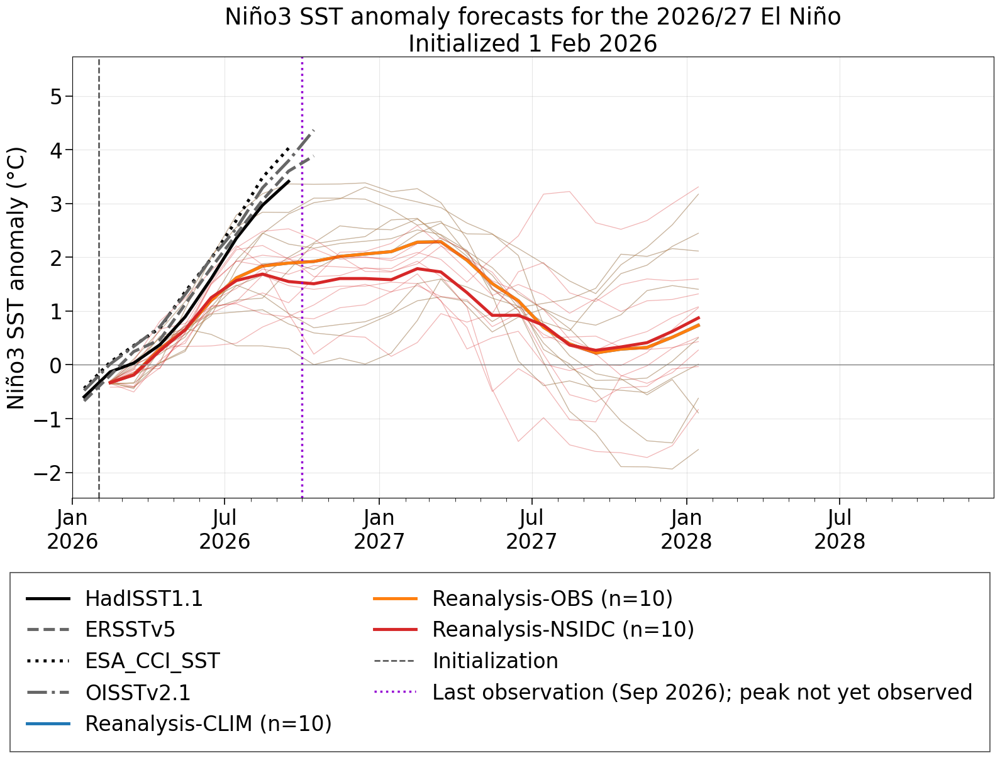

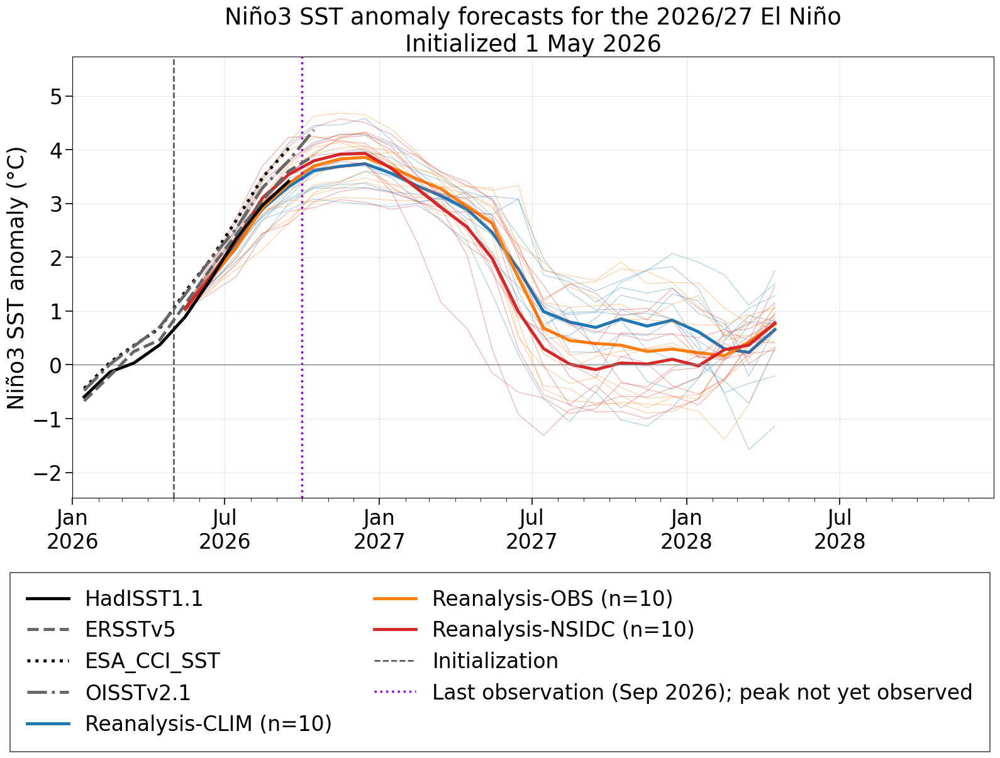

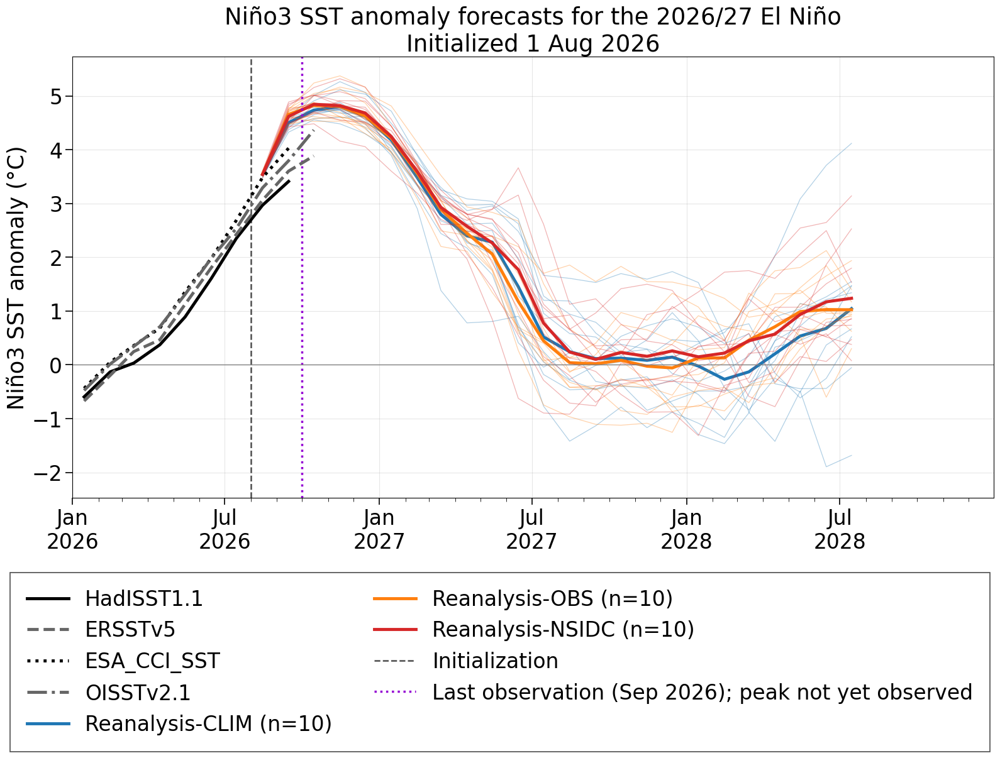

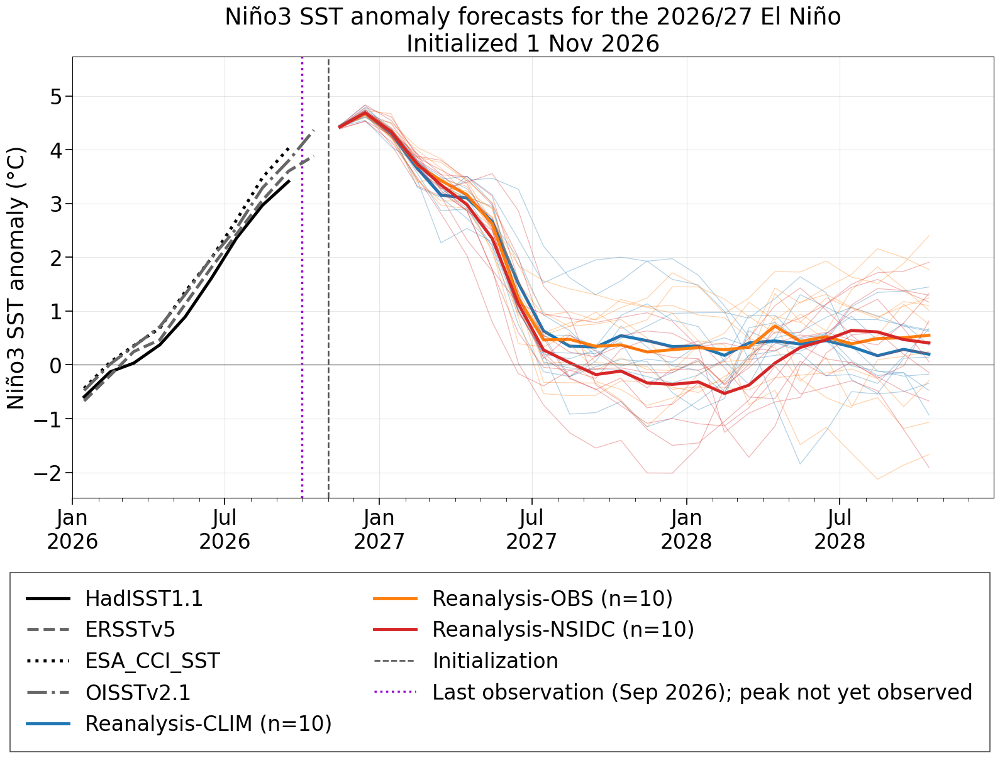

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino4_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino4_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino4_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino4_init11.png


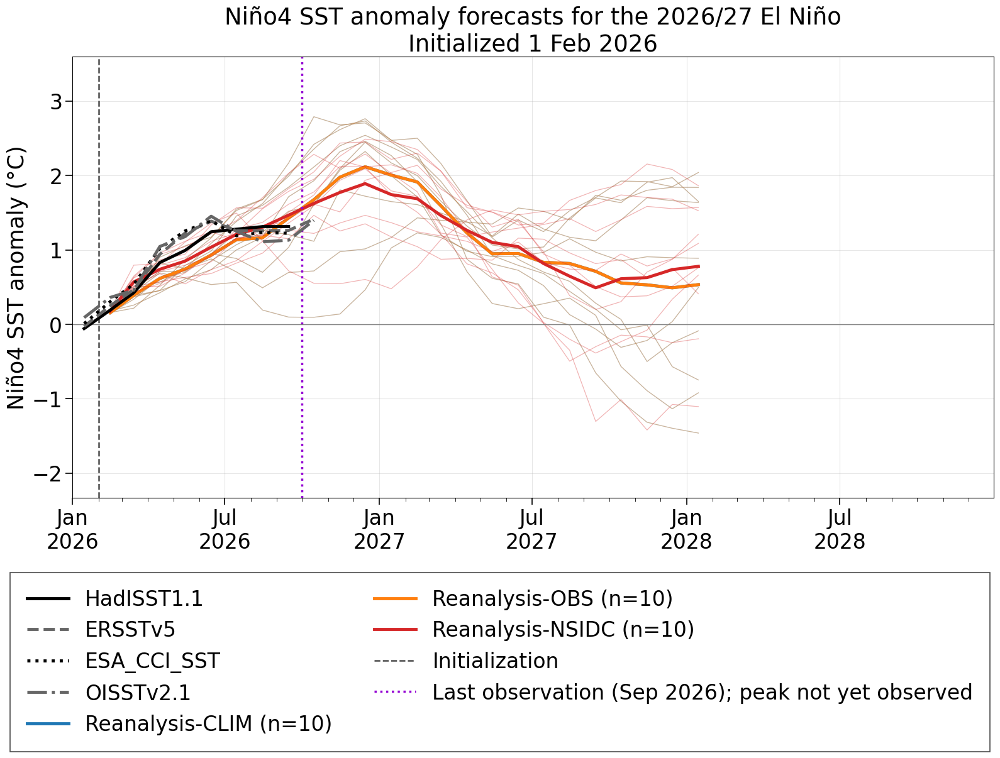

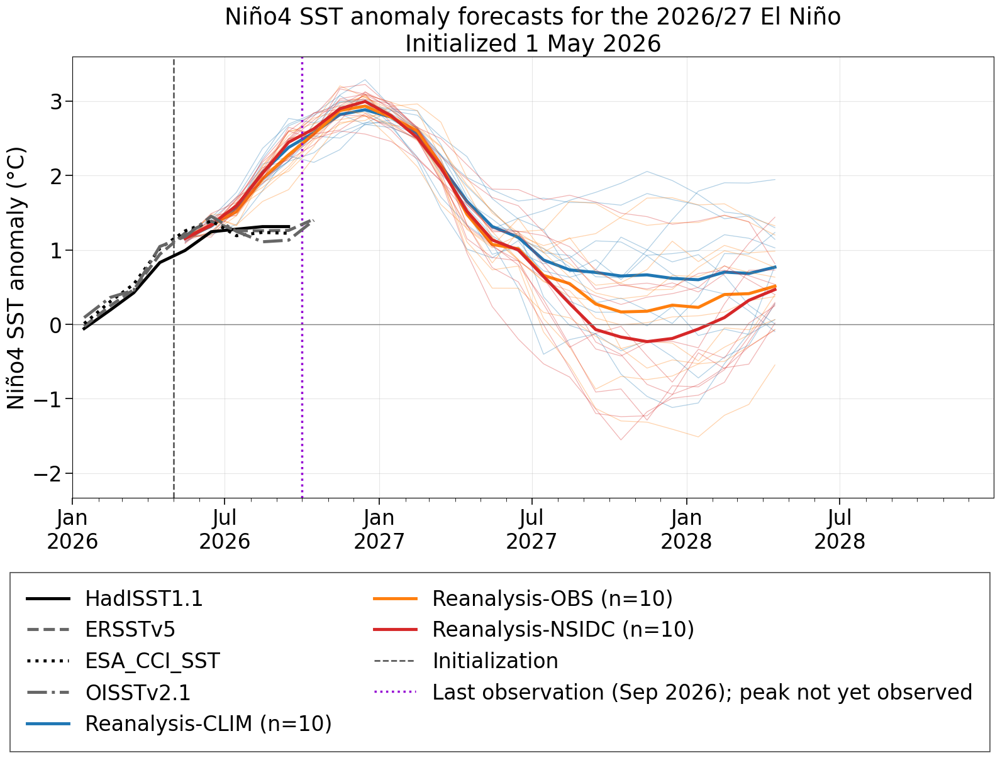

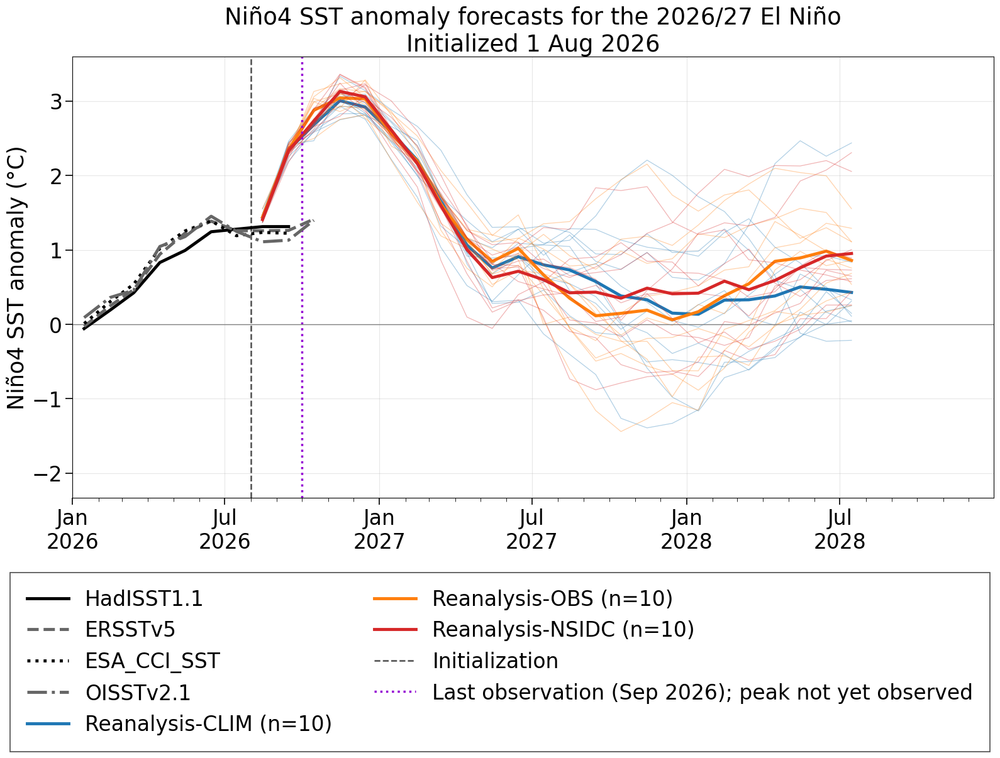

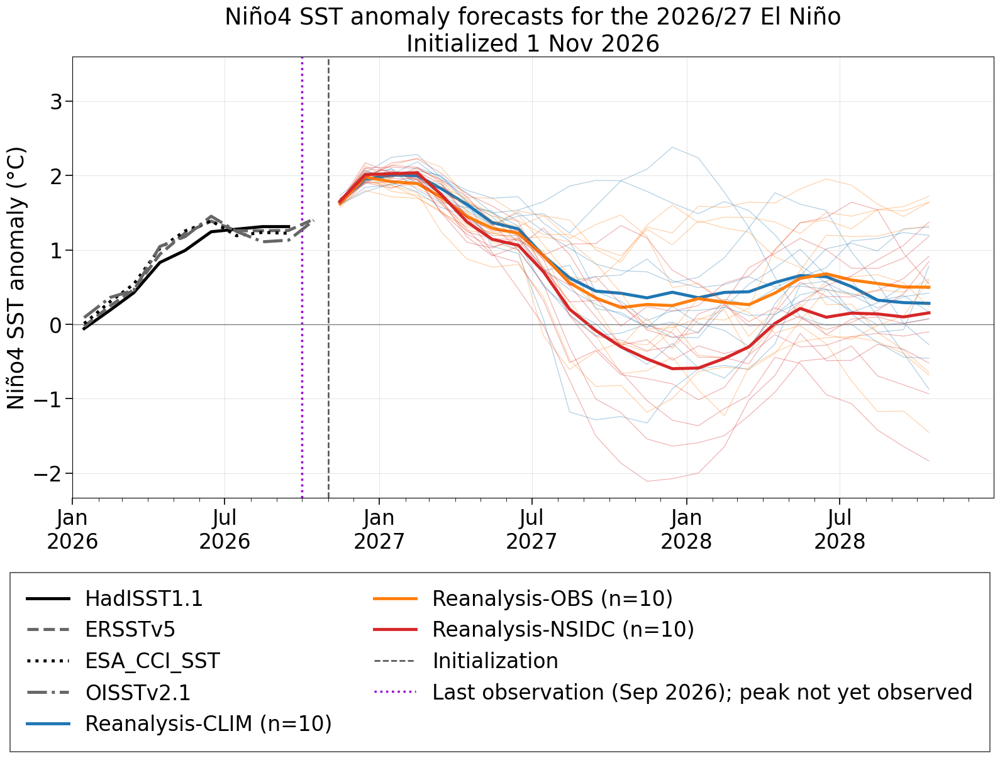

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino12_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino12_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino12_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino12_init11.png


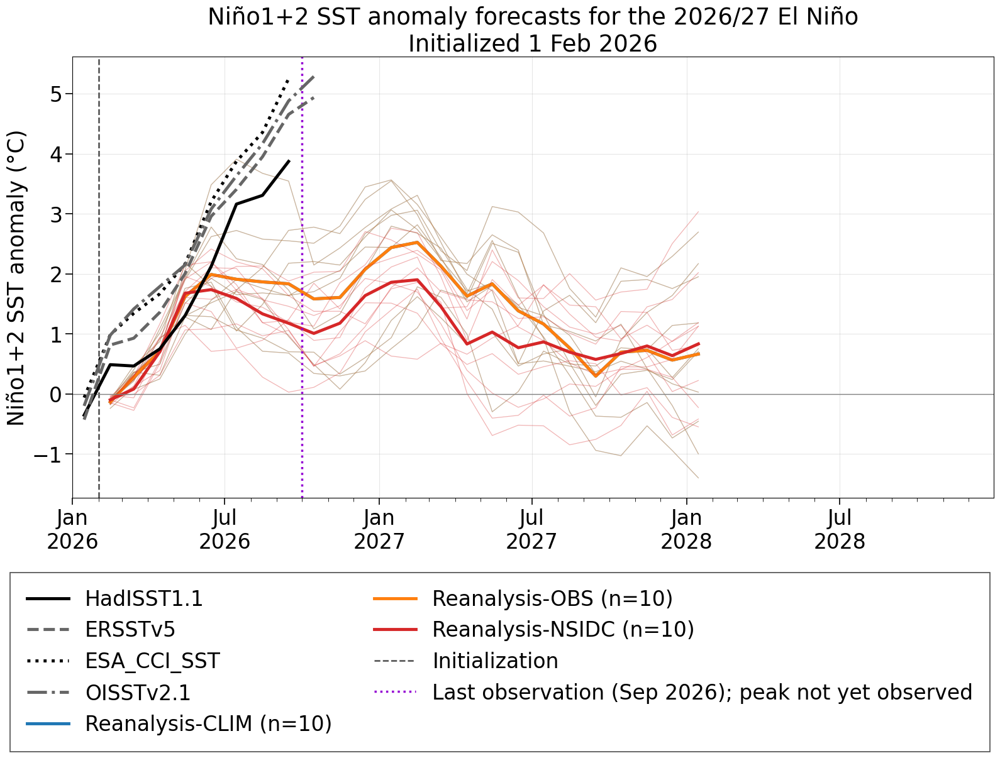

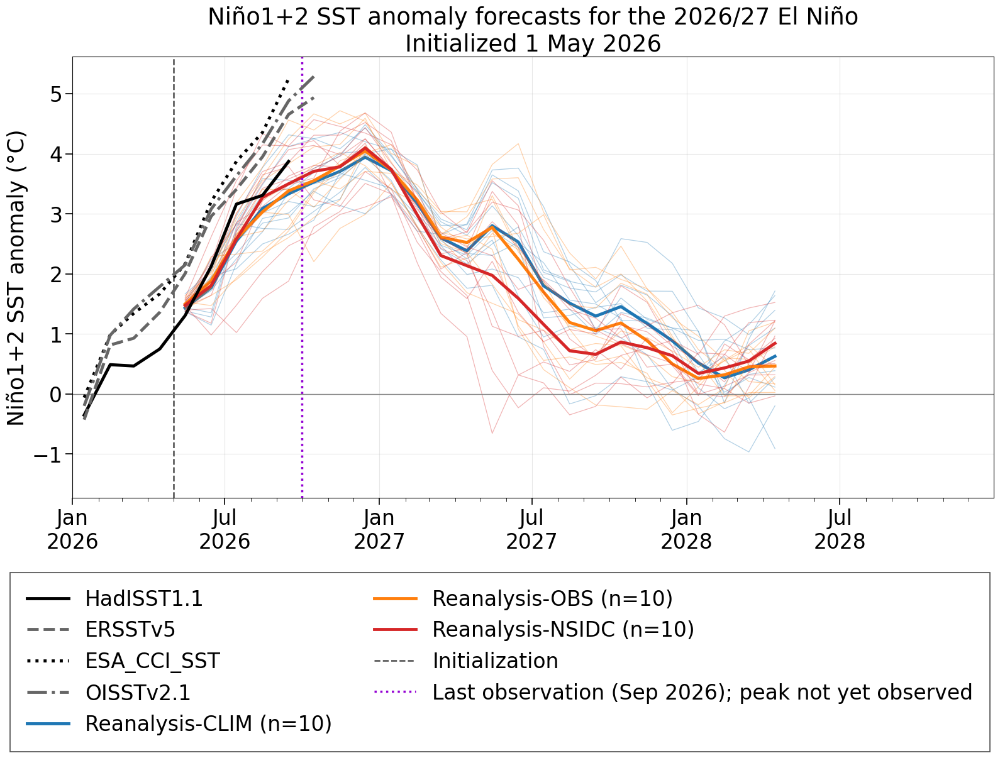

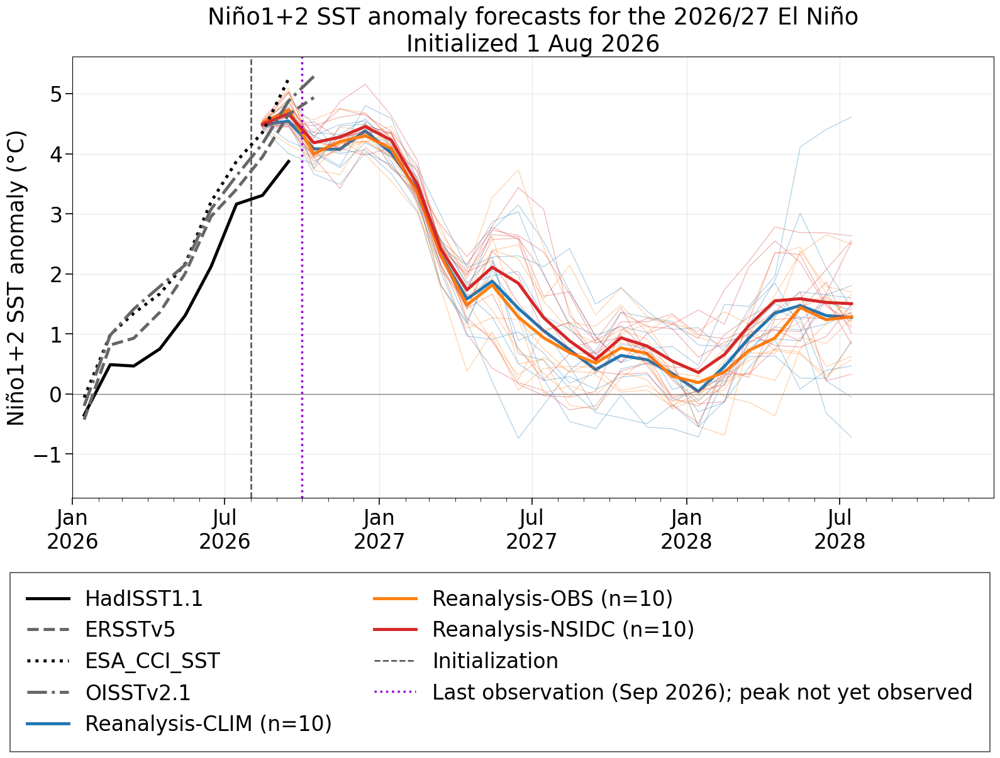

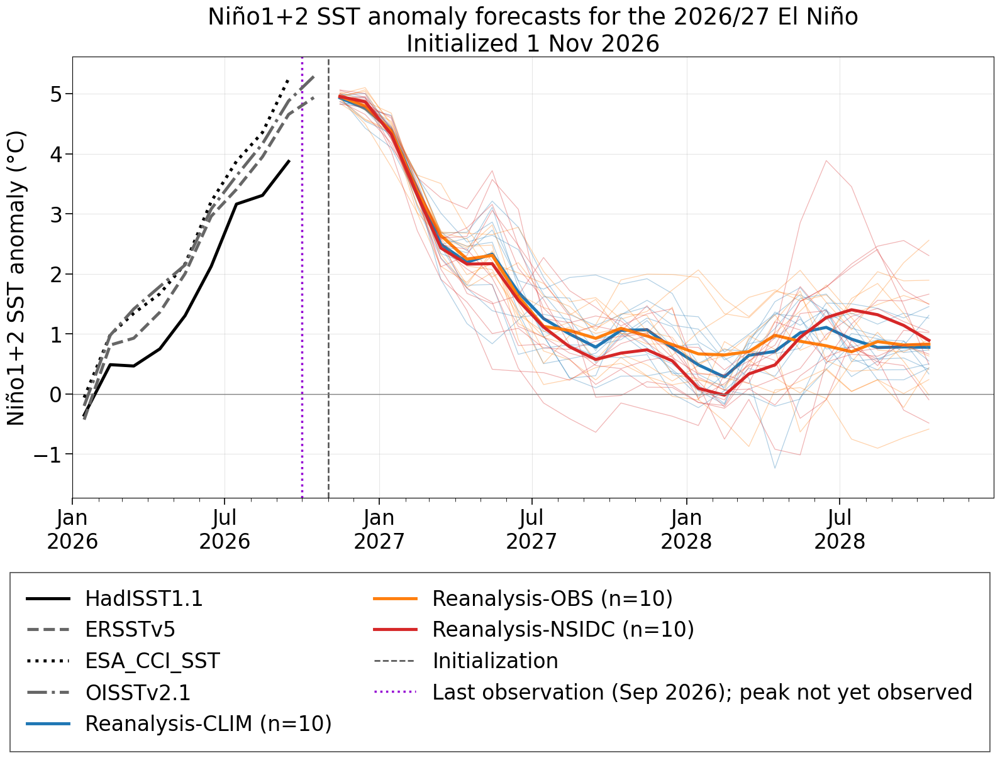

In [4]:
# ---- Figure setup (also used by the error/spread figure below) ----
fontz = 28        # base font size; every other size scales from it
fig_type = "png"  # saved figure type: "png", "pdf" (vector), "eps", "svg", ...
fig_dpi = 300     # resolution of saved raster figures
# True: one figure per initial month (shared y range across an event's starts); False: one 2x2 panel figure per event
SEPARATE_INITS = True
FIG = {
    "plume_figsize": (24, 12),
    "error_figsize": (24, 12),
    "single_figsize": (16, 9),      # one-start figures (SEPARATE_INITS)
    "single_legend_ncol": 2,
    "suptitle": fontz * 1.0,
    "title": fontz *0.95,                 # panel titles
    "label": fontz * 0.9,           # axis labels
    "tick": fontz * 0.85,
    "legend": fontz * 0.85,
    "legend_ncol": 4,               # columns of the legend below the panels
    "legend_box": {"frameon": True, "fancybox": False, "edgecolor": "0.3", "framealpha": 1.0,
                   "borderpad": 0.8, "columnspacing": 2.0},
    "obs_lw": 3.5,
    "ens_lw": 3.5,
    "member_lw": 0.9,
    "member_alpha": 0.35,
    "xlim_years": 3,                # x axis spans Jan of the start year through this many years (longer starts:
                                    # through the year of their last lead, rc.EXTENDED_STARTS)
    "ylim": None,                   # e.g. (-3, 5); None lets matplotlib choose
    "xtick_months": (1, 7),         # labelled months; minor ticks every month
    "suptitle_y": 1.03,             # suptitle height above the panels (figure fraction)
    "h_pad": 2.5,                   # vertical / horizontal gaps between panels (in font units)
    "w_pad": 1.5,
    "start_line": {"color": "0.3", "ls": "--", "lw": 1.8},
    "peak_frac": 0.9,               # peak period: contiguous months with obs >= peak_frac * observed peak
    "peak_shade": {"color": "darkviolet", "alpha": 0.15, "lw": 0},
}
INDEX_LABELS = {"Nino3.4": "Niño3.4", "ONI": "ONI (Niño3.4, 3-month mean)", "Nino3": "Niño3",
                "Nino4": "Niño4", "Nino12": "Niño1+2"}
# Short names for y-axis labels, e.g. "Niño3.4 SST anomaly (°C)"
AXIS_LABELS = {**INDEX_LABELS, "ONI": "ONI"}
PANEL_LETTERS = "abcdefgh"


def panel_title(k, year, init):
    return f"({PANEL_LETTERS[k]}) Initialized 1 {MONTH_NAMES[init]} {year}"


def month_end(t):
    return datetime(t.year + t.month // 12, t.month % 12 + 1, 1)


def observed_peak(index, year):
    """Observed peak period in the event years from the reference product.

    The period is the run of contiguous months around the observed maximum whose anomaly stays
    at or above FIG["peak_frac"] times that maximum. When the maximum is still rising at the end
    of the record ("ongoing"), the peak has not been observed yet.
    """
    obs = obs_indices[(year, OBS_REFERENCE)][index].sel(time=slice(f"{year}-01", f"{year + 1}-12")).dropna("time")
    vals, times = obs.values, obs["time"].values
    k = int(np.argmax(vals))
    threshold = FIG["peak_frac"] * vals[k]
    i0, i1 = k, k
    while i0 > 0 and vals[i0 - 1] >= threshold:
        i0 -= 1
    while i1 < len(vals) - 1 and vals[i1 + 1] >= threshold:
        i1 += 1
    first, last, end = (datetime(t.year, t.month, 1) for t in (times[i0], times[i1], times[-1]))
    return {"first": first, "last": last, "value": float(vals[k]), "ongoing": i1 == len(vals) - 1, "obs_end": end}


def mark_start_and_peak(ax, year, init, peak):
    ax.axvline(datetime(year, init, 1), label="Initialization", **FIG["start_line"])
    if rc.start_nlead(year, init) > rc.NLEAD:   # rc.EXTENDED_STARTS: drift of the leads 12 months earlier reused
        n = year * 12 + init - 1 + rc.NLEAD
        ext = datetime(n // 12, n % 12 + 1, 1)
        ax.axvline(ext, color="0.3", ls=":", lw=1.8,
                   label=f"From {ext:%b %Y}: drift correction of the same month a year earlier (Reanalysis runs {rc.NLEAD} months)")
    if peak["ongoing"]:
        ax.axvline(month_end(peak["obs_end"]), color=FIG["peak_shade"]["color"], ls=":", lw=2.5,
                   label=f"Last observation ({peak['obs_end']:%b %Y}); peak not yet observed")
        return
    first, last = peak["first"], peak["last"]
    period = f"{first:%b %Y}" if first == last else f"{first:%b %Y}–{last:%b %Y}"
    ax.axvspan(first, month_end(last), label=f"Observed peak period ({period}; max {peak['value']:.1f} °C)",
               zorder=0, **FIG["peak_shade"])


def init_axes(year, figsize=None):
    """Axes for the event's starts as [(fig, ax, init)]: one figure per start (SEPARATE_INITS)
    or one 2x2 figure whose unused panels are hidden."""
    inits = EVENTS[year]["init_months"]
    if SEPARATE_INITS:
        return [(*plt.subplots(figsize=FIG["single_figsize"]), init) for init in inits]
    fig, axes = plt.subplots(2, 2, figsize=figsize or FIG["plume_figsize"], sharey=True)
    for ax in axes.flat[len(inits):]:
        ax.set_visible(False)
    return [(fig, ax, init) for ax, init in zip(axes.flat, inits)]


def format_axis(ax, year, ylabel=None, init=None):
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=FIG["xtick_months"]))
    ax.xaxis.set_minor_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.tick_params(axis="both", which="major", labelsize=FIG["tick"], length=8, width=1.2)
    ax.tick_params(axis="x", which="minor", length=4)
    last_year = year + FIG["xlim_years"] - 1
    if init is not None:   # a start longer than rc.NLEAD months (rc.EXTENDED_STARTS) extends the axis to its last lead
        last_year = max(last_year, (year * 12 + init - 1 + rc.start_nlead(year, init) - 1) // 12)
    ax.set_xlim(datetime(year, 1, 1), datetime(last_year, 12, 31))
    if FIG["ylim"] is not None:
        ax.set_ylim(*FIG["ylim"])
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=FIG["label"])
    ax.axhline(0.0, color="0.5", lw=1.0)
    ax.grid(alpha=0.3)


def add_bottom_legend(fig, ax, ncol=None, fontsize=None, **kwargs):
    handles, labels = ax.get_legend_handles_labels()
    legend = fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=ncol or FIG["legend_ncol"],
                        fontsize=fontsize or FIG["legend"], **FIG["legend_box"], **kwargs)
    legend.get_frame().set_linewidth(1.2)


def save_fig(fig, *parts):
    print(rc.save_figure(fig, NOTEBOOK, *parts, dpi=fig_dpi, ext=fig_type))


def finish_figures(panels, year, title, *parts):
    """Titles, legend and saving for init_axes panels. Separate figures share the y range so the
    starts compare directly and are saved with an initNN suffix; the 2x2 figure gets panel letters."""
    if SEPARATE_INITS:
        if FIG["ylim"] is None:
            lo = min(ax.get_ylim()[0] for _, ax, _ in panels)
            hi = max(ax.get_ylim()[1] for _, ax, _ in panels)
            for _, ax, _ in panels:
                ax.set_ylim(lo, hi)
        for fig, ax, init in panels:
            ax.set_title(f"{title}\nInitialized 1 {MONTH_NAMES[init]} {year}", fontsize=FIG["title"])
            fig.tight_layout()
            add_bottom_legend(fig, ax, ncol=FIG["single_legend_ncol"])
            save_fig(fig, *parts, f"init{init:02d}")
        # plt.show() would display (and close) all open figures at the first call, before the later
        # ones have their title and legend; show each finished figure on its own instead.
        for fig in dict.fromkeys(f for f, _, _ in panels):
            display(fig)
            plt.close(fig)
        return
    fig = panels[0][0]
    for k, (_, ax, init) in enumerate(panels):
        ax.set_title(panel_title(k, year, init), fontsize=FIG["title"], loc="left")
    fig.suptitle(title.replace("\n", " "), fontsize=FIG["suptitle"], y=FIG["suptitle_y"])
    fig.tight_layout(h_pad=FIG["h_pad"], w_pad=FIG["w_pad"])
    add_bottom_legend(fig, panels[0][1])
    save_fig(fig, *parts)
    plt.show()


def plot_plume(index, year):
    peak = observed_peak(index, year)
    panels = init_axes(year)
    for _, ax, init in panels:
        for product, style in OBS_PRODUCTS.items():
            obs = obs_indices[(year, product)][index]
            ax.plot(to_datetime(obs["time"].values), obs, color=style["color"], ls=style["ls"],
                    lw=FIG["obs_lw"], label=product, zorder=6)
        for case in CASES:
            ds = fc_index.get((year, case, init))
            if ds is None:
                continue
            color, x = CASES[case]["color"], to_datetime(ds["time"].values)
            for member in ds["member"].values:
                ax.plot(x, ds[index].sel(member=member), color=color, lw=FIG["member_lw"], alpha=FIG["member_alpha"])
            ax.plot(x, ds[index].mean("member"), color=color, lw=FIG["ens_lw"],
                    label=f"{case} (n={ds.sizes['member']})")
        mark_start_and_peak(ax, year, init, peak)
        format_axis(ax, year, f"{AXIS_LABELS.get(index, index)} SST anomaly (°C)" if ax.get_subplotspec().is_first_col() else None,
                    init=init if SEPARATE_INITS else None)
    finish_figures(panels, year, f"{INDEX_LABELS.get(index, index)} SST anomaly forecasts for the {EVENTS[year]['label']}",
                   "rtenso2026", "enso_plume", f"y{year}", index)


for year in EVENTS:
    for index in INDICES:
        plot_plume(index, year)


### IRI-style seasonal plumes

Same forecasts in the layout of the IRI/CCSR ENSO prediction plume: 3-month running-season means of an index (Niño3.4 by default). One marker line per case is the case's ensemble mean of the season means, with its members as thin lines of the same colour (`IRI["show_members"]`); the thick navy line is the combined average of the cases, with equal weight per case. On the left are the observed season ending the month before the start (e.g. NDJ for a Feb start) and the observed month before the start, for every product in `OBS_PRODUCTS` (`IRI["obs_products"]`; line styles as in the monthly plumes). Grey dashed lines join that month to each case's first season. The season that straddles the start (e.g. JFM) is left blank, as in IRI. When the target seasons are observed, the verification lines (`IRI["show_verification"]`) show them for each product; the reference product (`OBS_REFERENCE`) has the large stars, and the grey connectors start from it. Dash-dot lines mark ±0.5 °C. For the 1 Feb 2026 start, `Reanalysis-CLIM` and `Reanalysis-OBS` are bit-identical, so the combined average counts that state twice.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2015_nino3_4_init02.png


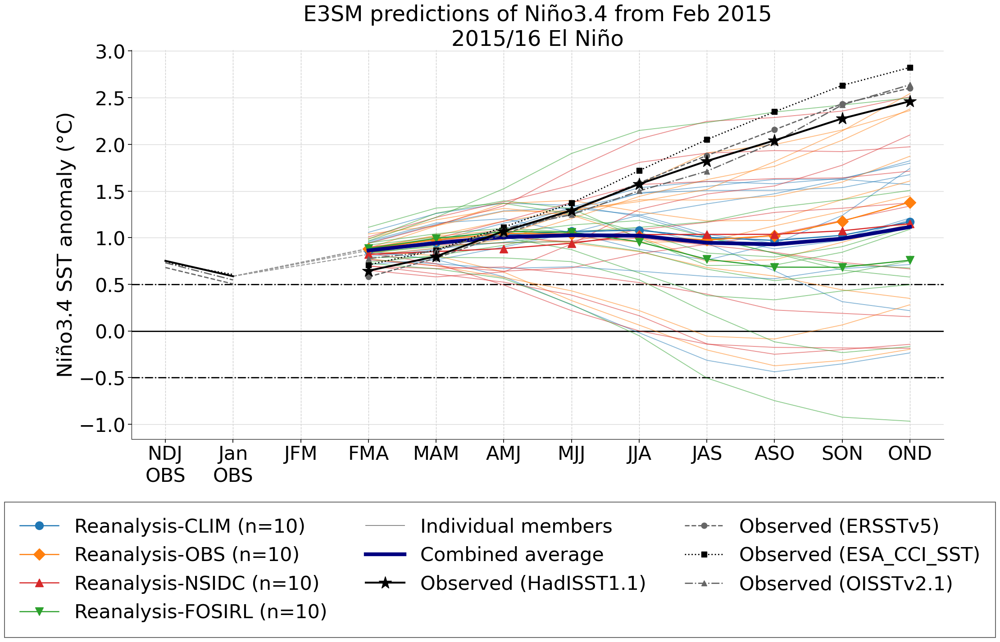

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2015_nino3_4_init05.png


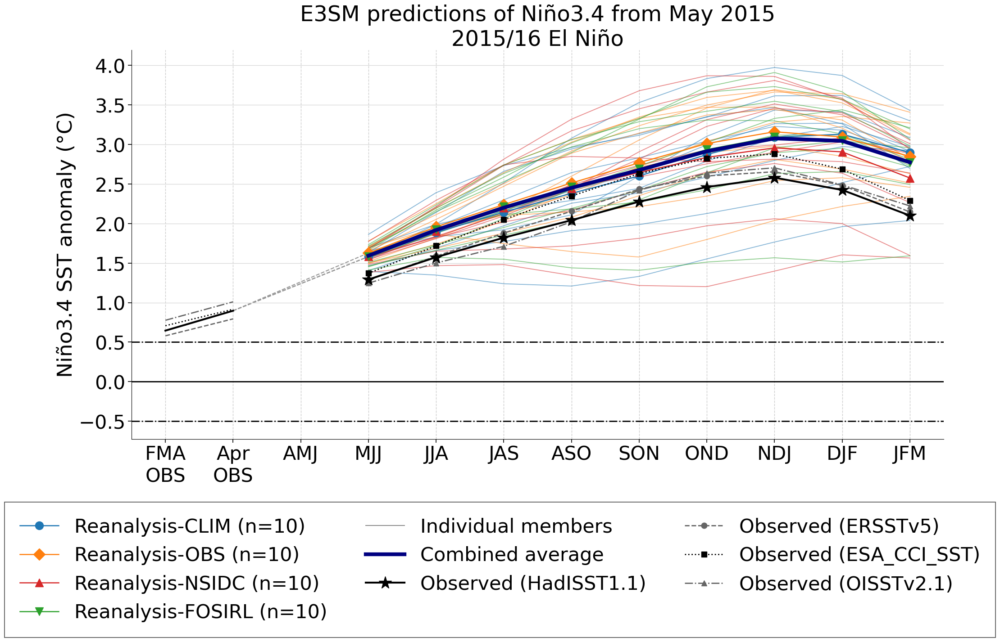

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2015_nino3_4_init08.png


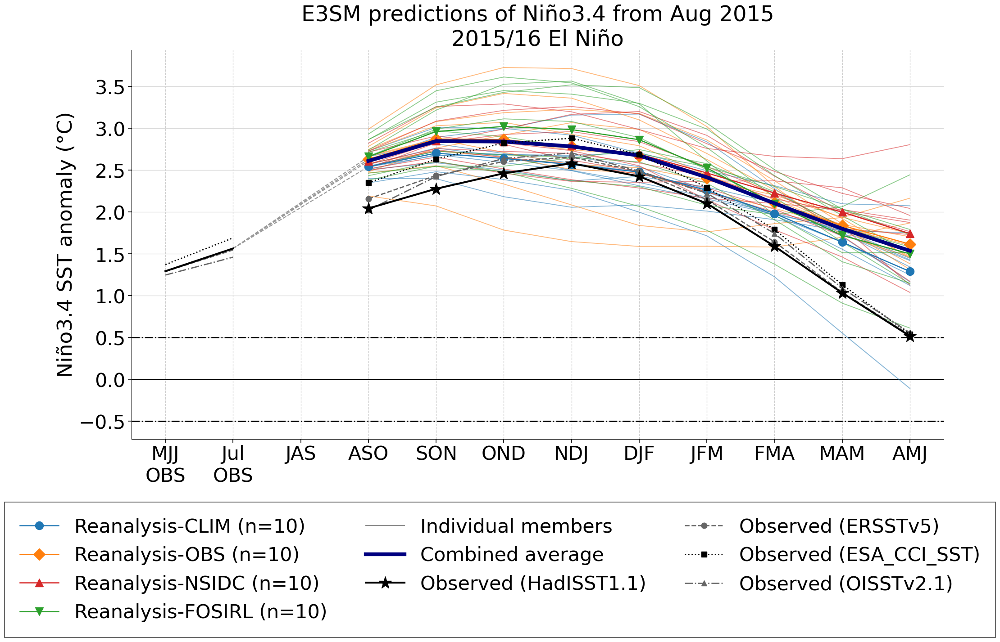

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2015_nino3_4_init11.png


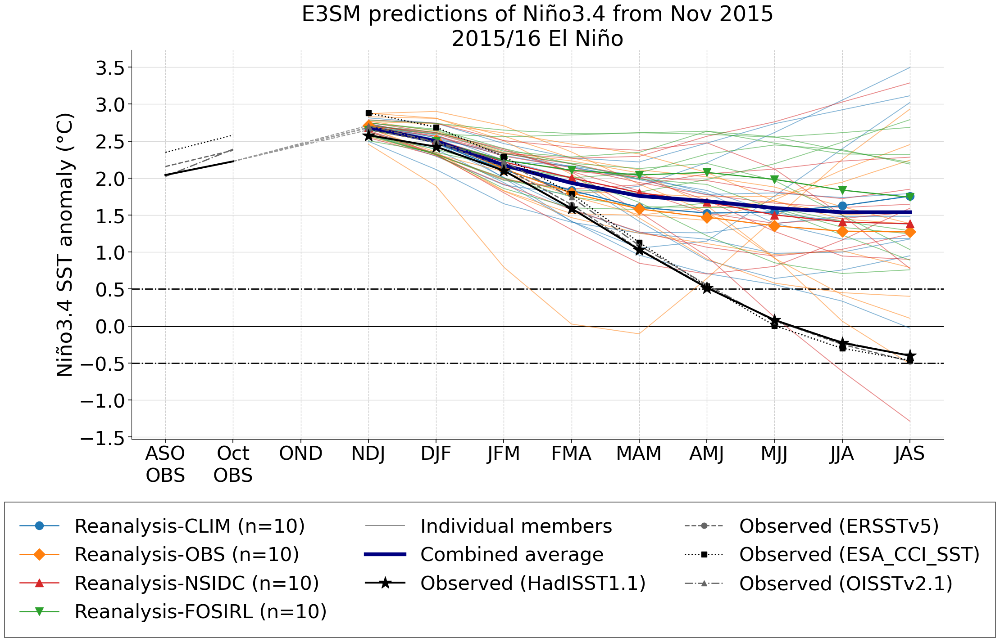

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2026_nino3_4_init02.png


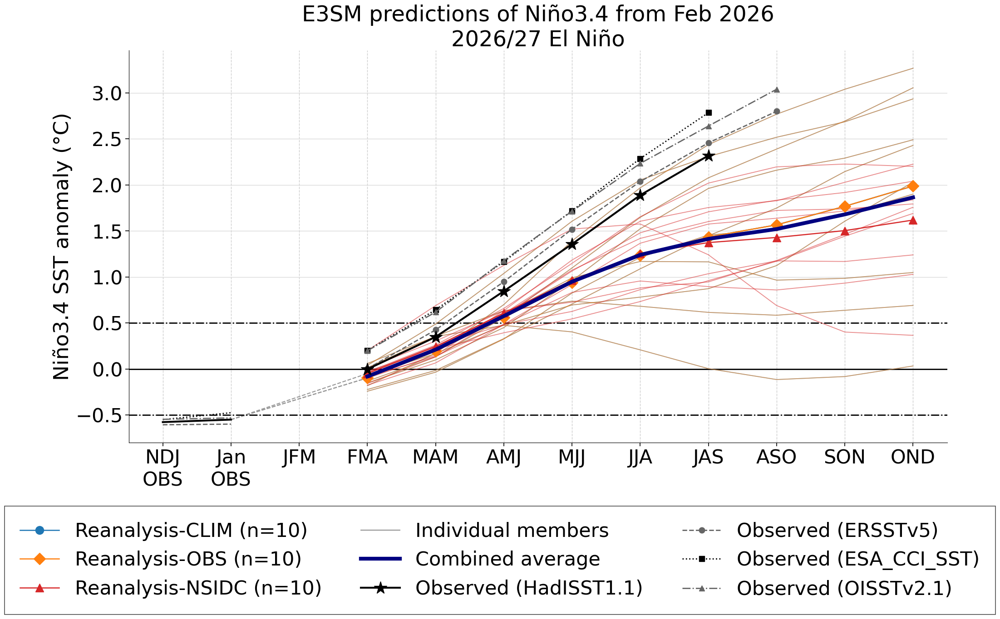

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2026_nino3_4_init05.png


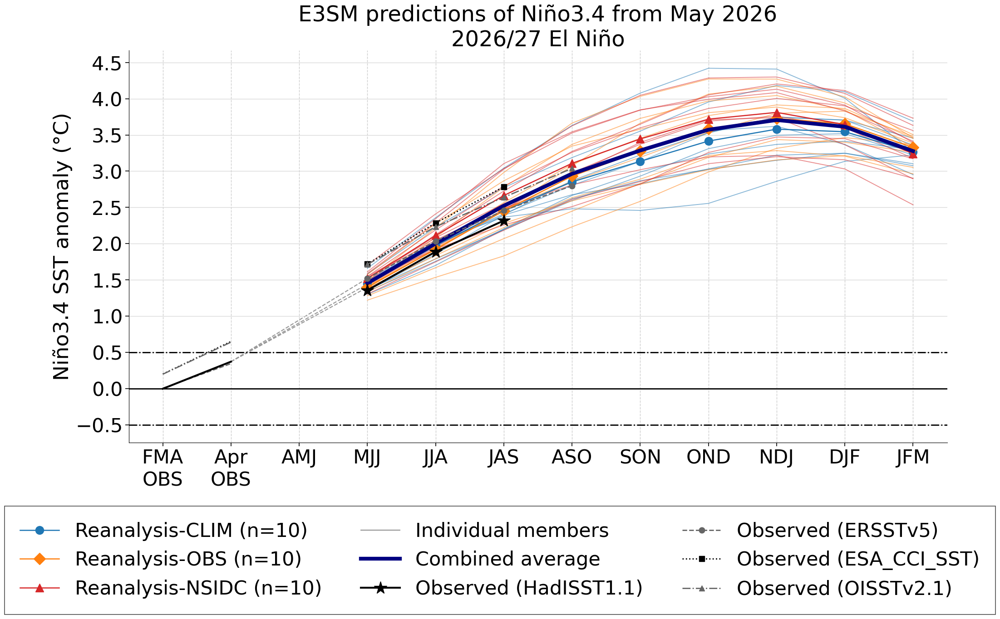

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2026_nino3_4_init08.png


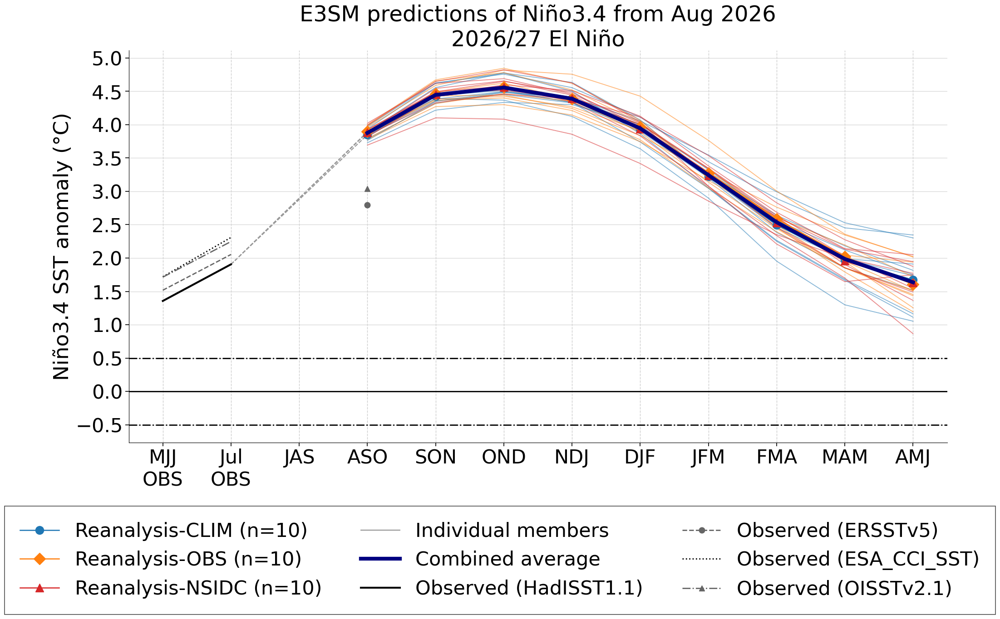

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_iri_y2026_nino3_4_init11.png


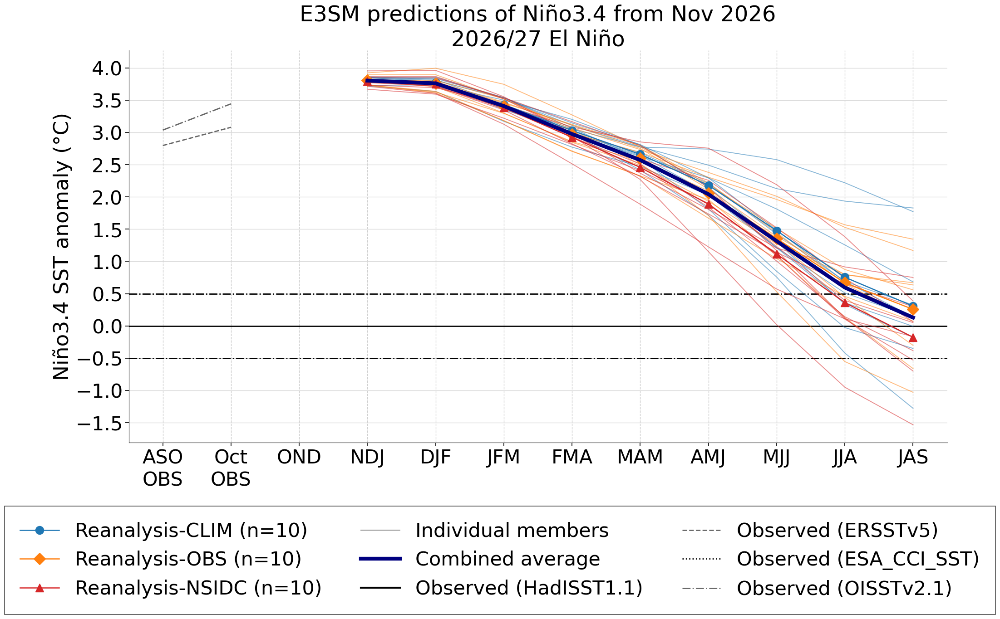

In [5]:
# ---- IRI-style plume setup ----
IRI = {
    "indices": ["Nino3.4"],          # any of INDICES; "ONI" would double-smooth, so it is not used here
    "n_seasons": 9,                  # forecast seasons shown (lead k covers months k..k+2 after the start)
    "figsize": (20, 11),
    "ylim": None,                    # e.g. (-2, 2) as in IRI; None fits the data, with ticks every 0.5
    "threshold": 0.5,                # El Niño / La Niña lines
    "case_lw": 1.8,
    "case_ms": 13,
    "avg_lw": 6.0,
    "avg_color": "navy",
    "connector": {"color": "0.6", "ls": "--", "lw": 1.6},
    "markers": ["o", "D", "^", "v", "s", "P", "X"],
    "show_members": True,            # thin member lines (case colour) behind the case means
    "show_verification": True,       # observed target seasons, where available
    "obs_products": "all",           # "all": every OBS_PRODUCTS entry; "reference": OBS_REFERENCE only
    "obs_markers": ["o", "s", "^", "D"],   # verification markers of the non-reference products
    "legend_ncol": 3,                # columns of the legend below the axes
    "font_scale": 1.3,               # multiplies the FIG font sizes for these figures
}
MONTH_LETTERS = "JFMAMJJASOND"


def add_months(year, month, k):
    n = year * 12 + month - 1 + k
    return n // 12, n % 12 + 1


def season_label(year, month):
    """Initials of the 3-month season starting at (year, month), e.g. FMA."""
    return "".join(MONTH_LETTERS[add_months(year, month, i)[1] - 1] for i in range(3))


def season_means(da, n):
    """3-month means over leads k..k+2, k = 0..n-1, as a new "season" dim."""
    return xr.concat([da.isel(lead=slice(k, k + 3)).mean("lead") for k in range(n)], dim="season")


_obs_iri = {}
def obs_iri(year, index, product=OBS_REFERENCE):
    """Observed index monthly anomalies of ``product`` from Jan of the year before (for NDJ-OBS etc.)."""
    if (year, index, product) not in _obs_iri:
        ts = rc.obs_anomaly("TS", years=(year - 1, year + 2), mode=derivation_mode, product=product)
        _obs_iri[(year, index, product)] = rc.nino_indices(ts, [index])[index].load()
    return _obs_iri[(year, index, product)]


def iri_products():
    """Observed products drawn on the IRI plumes, the reference first."""
    if IRI["obs_products"] == "reference":
        return [OBS_REFERENCE]
    return [OBS_REFERENCE] + [p for p in OBS_PRODUCTS if p != OBS_REFERENCE]


def plot_iri_plume(index, year, init):
    cases = {c: fc_index[(year, c, init)] for c in CASES if (year, c, init) in fc_index}
    if not cases:
        return
    n = min(IRI["n_seasons"], min(ds.sizes["lead"] for ds in cases.values()) - 2)
    prev = [add_months(year, init, -k) for k in (3, 2, 1)]          # e.g. Nov, Dec, Jan for a Feb start
    obs_x = [0, 1]
    obs_all = {p: obs_iri(year, index, p) for p in iri_products()}
    obs_y_all = {p: [float(rc.obs_target_mean(o, prev)), float(rc.obs_target_mean(o, prev[-1:]))]
                 for p, o in obs_all.items()}
    obs_y = obs_y_all[OBS_REFERENCE]                                  # the connectors start from the reference
    x = np.arange(3, 3 + n)                                           # x = 2 is the blank straddling season
    labels = [f"{season_label(*prev[0])}\nOBS", f"{datetime(2000, prev[-1][1], 1):%b}\nOBS",
              season_label(*prev[-1])] + [season_label(*add_months(year, init, k)) for k in range(n)]

    fig, ax = plt.subplots(figsize=IRI["figsize"])
    case_means = []
    for k, (case, ds) in enumerate(cases.items()):
        seas = season_means(ds[index], n)
        mean = seas.mean("member")
        case_means.append(mean)
        color, marker = CASES[case]["color"], IRI["markers"][k % len(IRI["markers"])]
        if IRI["show_members"]:
            for member in seas["member"].values:
                ax.plot(x, seas.sel(member=member), color=color, lw=FIG["member_lw"] * 1.5, alpha=FIG["member_alpha"] * 1.5,
                        zorder=3)
        ax.plot([obs_x[-1], x[0]], [obs_y[-1], float(mean[0])], zorder=1, **IRI["connector"])
        ax.plot(x, mean, color=color, lw=IRI["case_lw"], marker=marker, ms=IRI["case_ms"], mec=color,
                label=f"{case} (n={ds.sizes['member']})", zorder=4)
    if IRI["show_members"]:
        ax.plot([], [], color="0.4", lw=FIG["member_lw"] * 1.5, alpha=0.8, label="Individual members")
    avg = xr.concat(case_means, dim="case").mean("case")
    ax.plot(x, avg, color=IRI["avg_color"], lw=IRI["avg_lw"], label="Combined average", zorder=5)
    markers = iter(IRI["obs_markers"])
    for p, o in obs_all.items():
        ref = p == OBS_REFERENCE
        style = OBS_PRODUCTS.get(p, {"color": "k", "ls": "-"})
        lw = 3.0 if ref else 2.0
        verif = [float(rc.obs_target_mean(o, [add_months(year, init, k + i) for i in range(3)])) for k in range(n)]
        has_verif = IRI["show_verification"] and np.isfinite(verif).any()
        marker, ms = ("*", IRI["case_ms"] * 1.6) if ref else (next(markers, "o"), IRI["case_ms"] * 0.7)
        # one legend entry per product: its line style, plus its verification marker when shown
        ax.plot(obs_x, obs_y_all[p], color=style["color"], ls=style["ls"], lw=lw, zorder=6 if ref else 5.5)
        ax.plot([], [], color=style["color"], ls=style["ls"], lw=lw, marker=marker if has_verif else None, ms=ms,
                label=f"Observed ({p})")
        if has_verif:
            ax.plot(x, verif, color=style["color"], ls=style["ls"], lw=lw, marker=marker, ms=ms,
                    zorder=6 if ref else 5.5)

    for xv in range(len(labels)):
        ax.axvline(xv, color="0.8", ls="--", lw=1.0, zorder=0)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.5))
    ax.grid(axis="y", color="0.85", lw=1.0, zorder=0)
    ax.axhline(0.0, color="k", lw=2.0, zorder=2)
    for sign in (1, -1):
        ax.axhline(sign * IRI["threshold"], color="k", ls="-.", lw=2.0, zorder=2)
    ax.set_xticks(range(len(labels)), labels)
    ax.set_xlim(-0.5, len(labels) - 0.5)
    if IRI["ylim"] is not None:
        ax.set_ylim(*IRI["ylim"])
    fs = {k: FIG[k] * IRI["font_scale"] for k in ("tick", "label", "title", "legend")}
    ax.tick_params(axis="both", labelsize=fs["tick"], length=6, width=1.2)
    ax.set_ylabel(f"{AXIS_LABELS.get(index, index)} SST anomaly (°C)", fontsize=fs["label"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.set_title(f"E3SM predictions of {INDEX_LABELS.get(index, index)} from {MONTH_NAMES[init]} {year}"
                 f"\n{EVENTS[year]['label']}", fontsize=fs["title"])
    fig.tight_layout()
    add_bottom_legend(fig, ax, ncol=IRI["legend_ncol"], fontsize=fs["legend"])
    save_fig(fig, "rtenso2026", "enso_plume_iri", f"y{year}", index, f"init{init:02d}")
    plt.show()


for year, event in EVENTS.items():
    for init in event["init_months"]:
        for index in IRI["indices"]:
            plot_iri_plume(index, year, init)


### RONI outlook (CPC style)

The forecasts in the layout of the NOAA CPC official ENSO outlook: the **Relative Oceanic Niño Index**
(RONI), CPC's operational ENSO index since February 2026 (van Oldenborgh et al. 2021). RONI is the
3-month running mean of the Niño3.4 SST anomaly minus the tropical-mean (20°S-20°N, ocean) SST anomaly,
multiplied by a constant so that its standard deviation equals the ONI's. Removing the tropical mean
takes out the warming trend and the tropics-wide warming that is not specific to ENSO.

* **Scaling**: the ratio σ(ONI) / σ(3-month Niño3.4 minus tropical mean) of `RONI["scale_product"]`
  (HadISST 1.1) over 1981-2010, applied to observations and to the model alike. CPC computes it from
  ERSSTv5; the value used is printed below.
* **Ensemble**: the `RONI["pool"]` cases pooled (`rc.POOLED_CASES`; a case that repeats an already
  pooled case member for member, the 1 Feb 2026 `clim` and `obs` runs, is counted once). Model anomalies
  are drift-corrected (`CLIM_METHOD`), and the model TS is masked to the observed ocean points.
* **Seasons**: centred 3-month means, as CPC's RONI, labelled by their three months: the season
  centred on lead k averages leads k-1..k+1. The first season is centred on the start month, so it
  holds only the two forecast months (e.g. "OND*" for a 1 Nov start: the Nov-Dec hindcast mean, the
  centred running mean truncated at the start of the record, as in ESP-Lab's RONI); the observed value
  of that season uses all three months. Shading: the 5-95%, 15-85% and 25-75% ranges of the pooled members; thin line: their mean.
  Black: observed RONI (`OBS_REFERENCE`) for the seasons already observed (`RONI["show_obs"]`).

One figure and one CSV (mean and percentiles by season) per event and start.

RONI scaling factor (HadISST1.1, 1981-2010): 1.168


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2015_init02.png


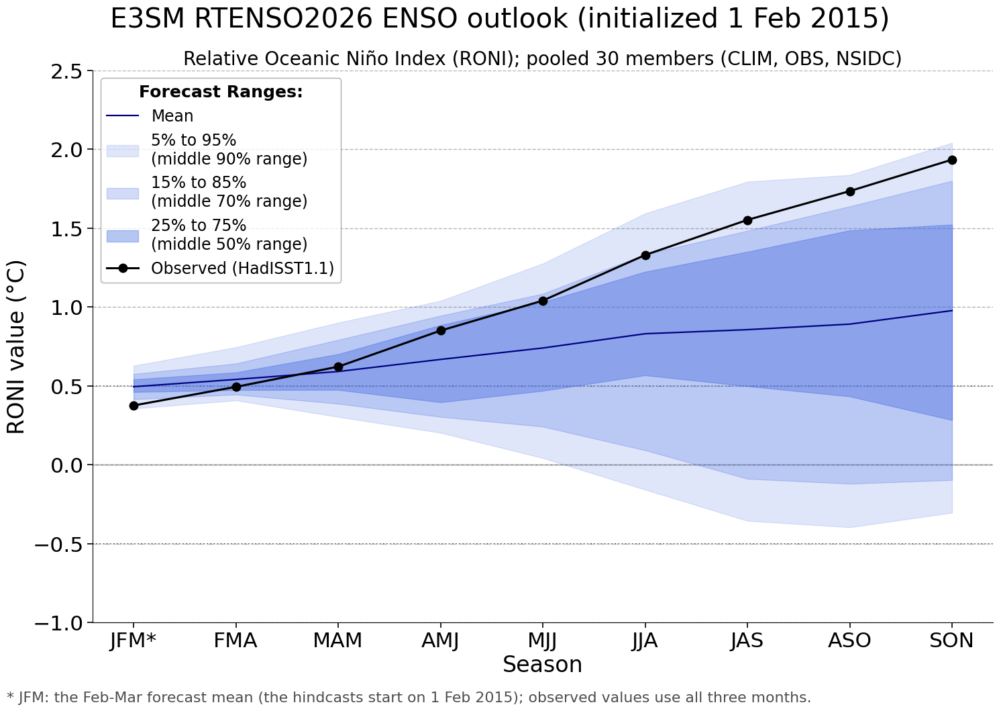

[2015 init02] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2015_init02.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2015_init05.png


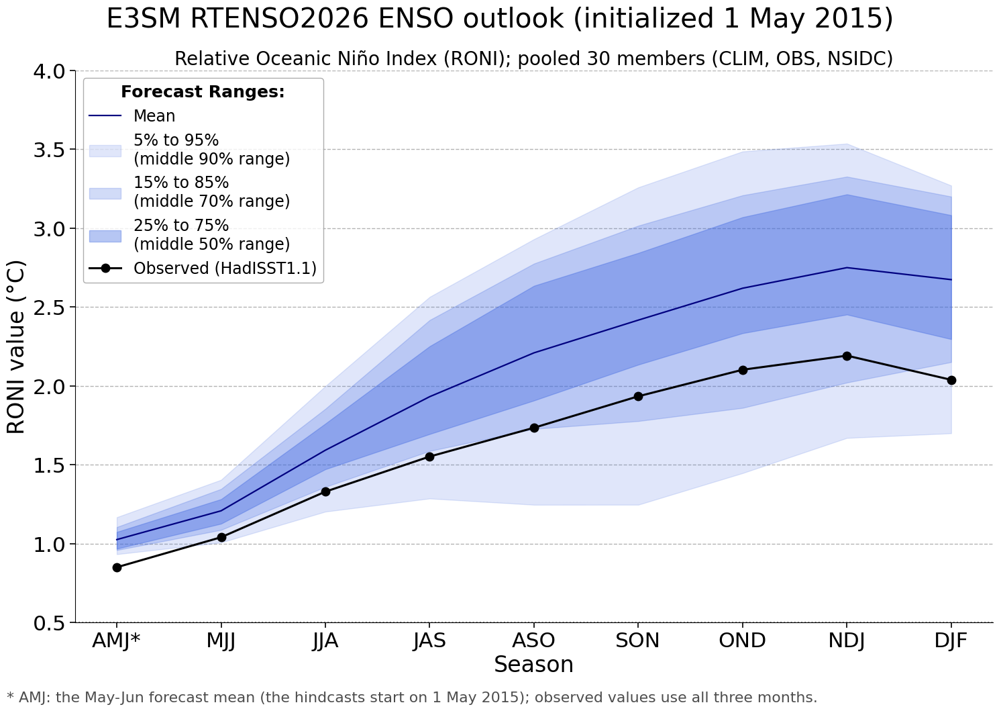

[2015 init05] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2015_init05.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2015_init08.png


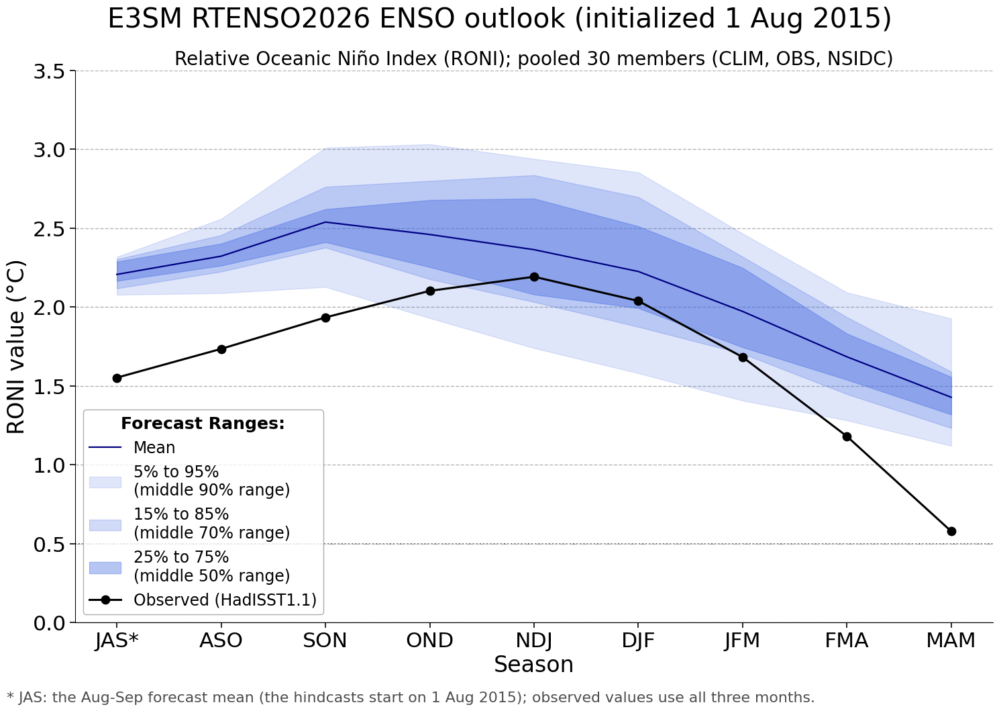

[2015 init08] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2015_init08.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2015_init11.png


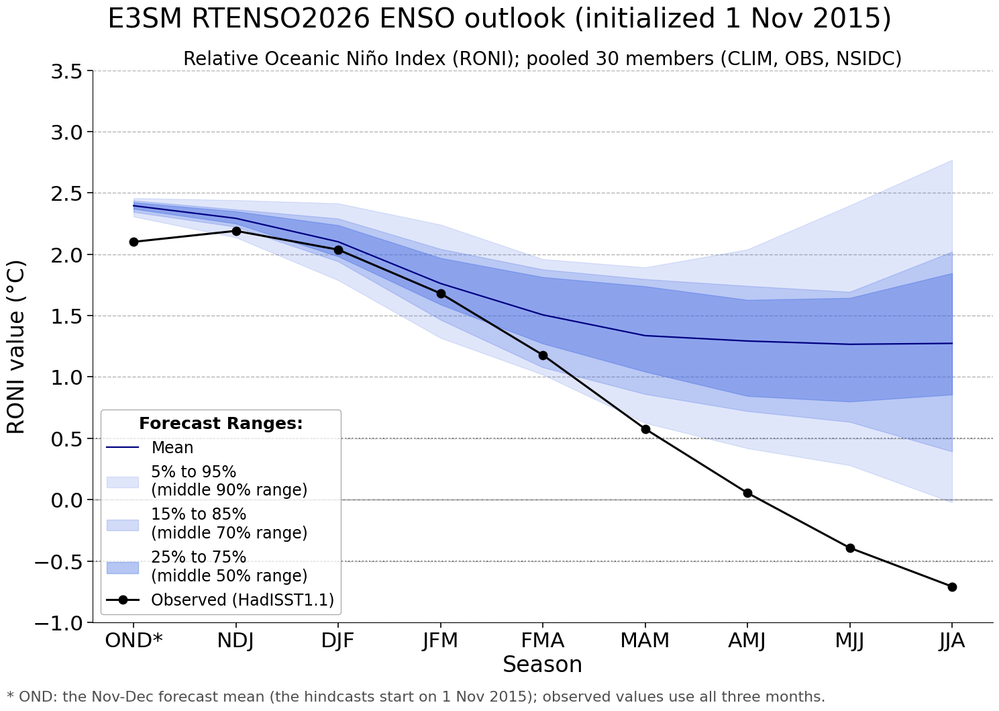

[2015 init11] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2015_init11.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2026_init02.png


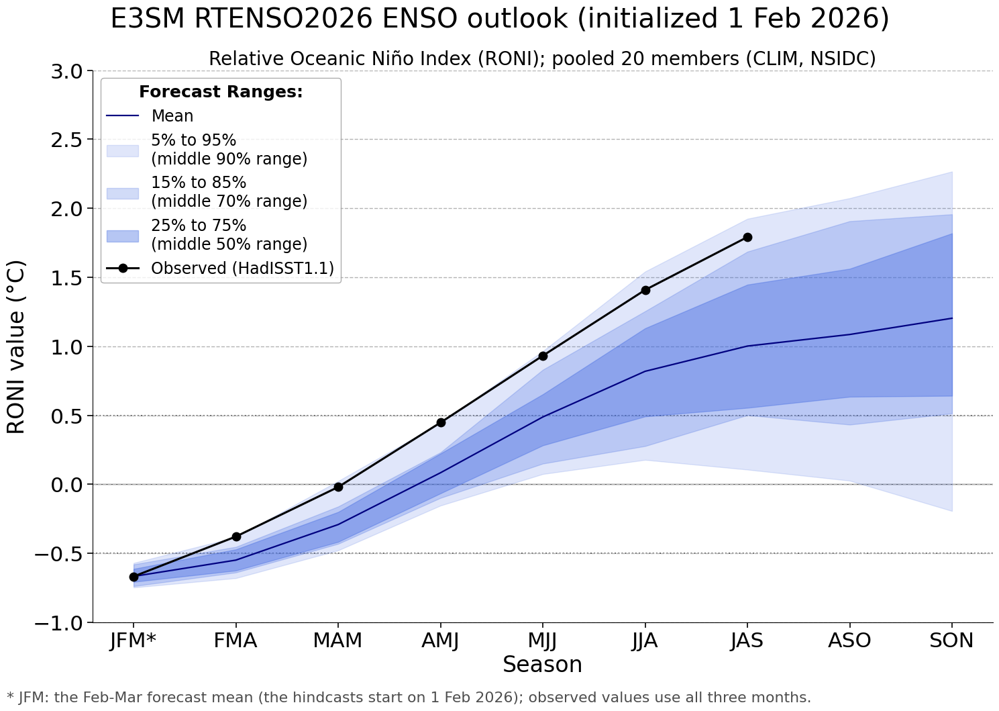

[2026 init02] 20 members from Reanalysis-CLIM, Reanalysis-NSIDC; Reanalysis-OBS skipped (identical to a pooled case) -> RTENSO2026_RONI_outlook_y2026_init02.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2026_init05.png


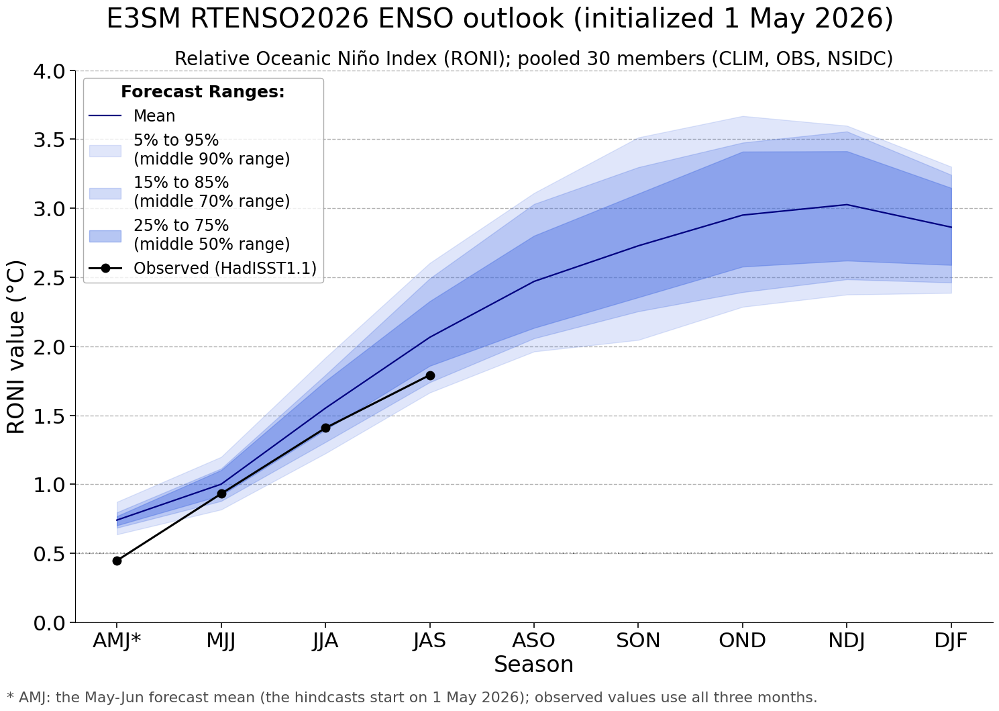

[2026 init05] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2026_init05.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2026_init08.png


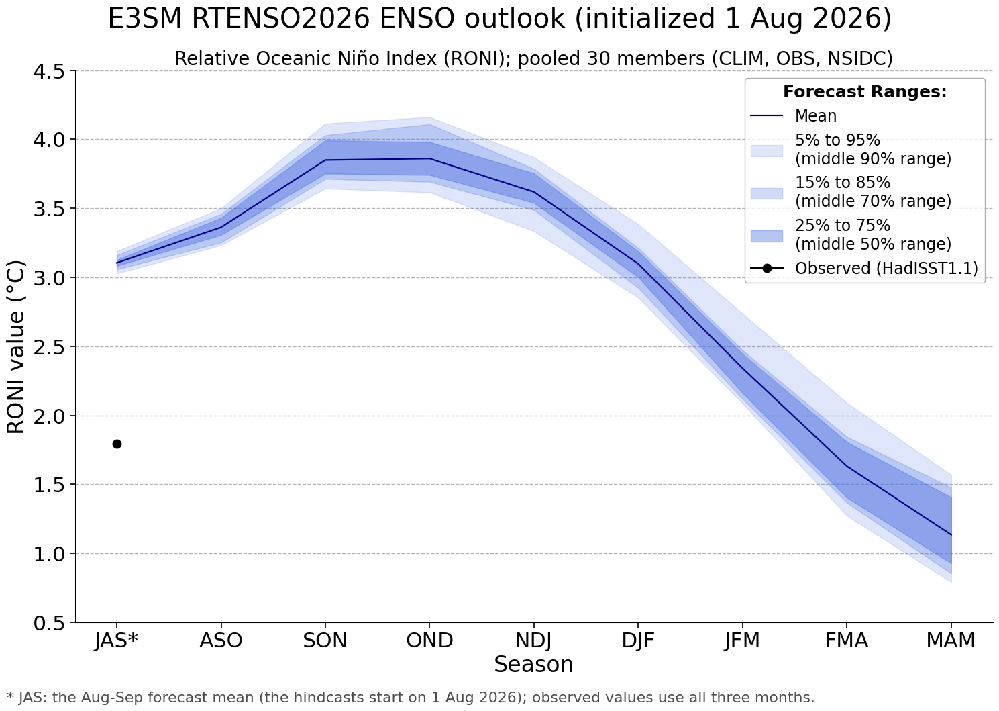

[2026 init08] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2026_init08.csv


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_roni_outlook_y2026_init11.png


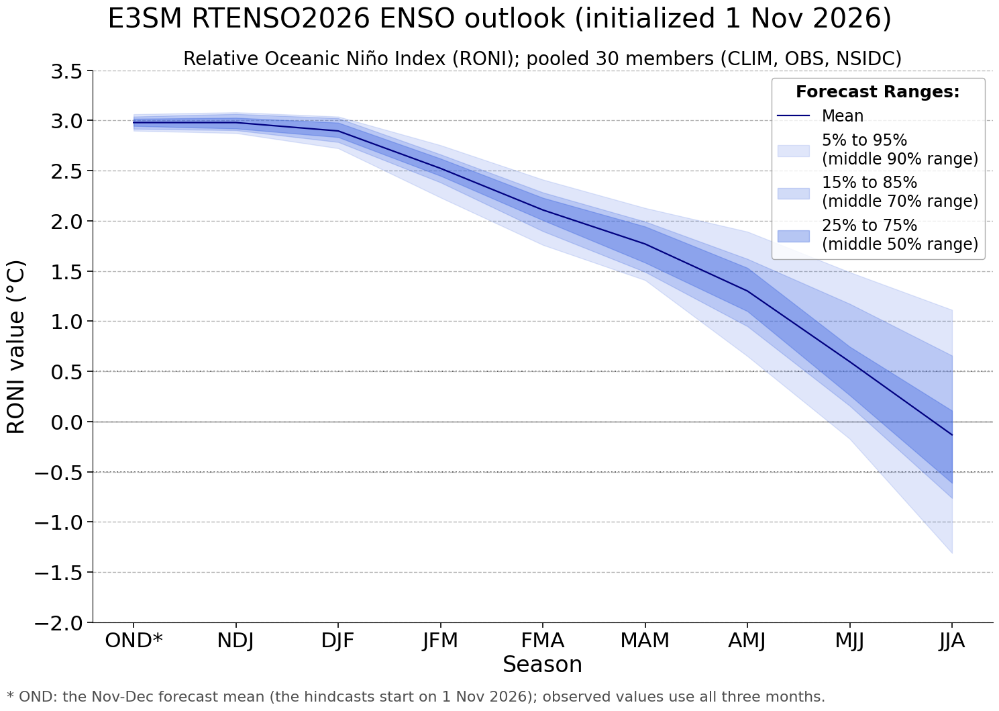

[2026 init11] 30 members from Reanalysis-CLIM, Reanalysis-OBS, Reanalysis-NSIDC -> RTENSO2026_RONI_outlook_y2026_init11.csv


In [6]:
# ---- RONI outlook setup (fonts, figure type and dpi follow FIG / fig_type / fig_dpi above) ----
RONI = {
    "n_seasons": 9,                  # forecast seasons shown, centred on leads 0..n-1 (the first holds 2 months)
    "pool": rc.POOLED_CASES,         # cases pooled into one ensemble
    "scale_product": OBS_REFERENCE,  # observations that set the RONI scaling factor (1981-2010)
    # (low, high percentile, legend text, alpha): drawn on top of each other, so the middle ranges darken
    "ranges": [(5, 95, "middle 90% range", 0.16), (15, 85, "middle 70% range", 0.24), (25, 75, "middle 50% range", 0.38)],
    "color": "royalblue",
    "mean_color": "navy",
    "mean_lw": 1.6,
    "show_obs": True,                # observed RONI for the seasons already observed
    "obs_ms": 9,
    "thresholds": (0.5, -0.5),       # El Niño / La Niña lines (dotted); () for none
    "ylim": None,                    # None: fit the 5-95% range and the observations, ticks every 0.5
    "figsize": (15, 10.5),
    "legend_loc": "best",            # e.g. "upper right" as in CPC; "best" avoids covering the bands
    "font_scale": 0.95,              # multiplies the FIG font sizes for these figures
}


def roni_scale(product=OBS_REFERENCE, years=rc.CLIM_YEARS):
    """sigma(ONI) / sigma(3-month mean of Nino3.4 minus the tropical mean) of ``product`` over ``years``."""
    ts = rc.obs_anomaly("TS", years=years, mode=derivation_mode, product=product)
    nino = rc.box_mean(ts, rc.NINO_REGIONS["Nino3.4"]).load()
    trop = rc.box_mean(ts, TROPICAL_BOX).load()
    oni = nino.rolling(time=3, center=True).mean()
    rel = (nino - trop).rolling(time=3, center=True).mean()
    return float(oni.std() / rel.std())


RONI_SCALE = roni_scale(RONI["scale_product"])
print(f"RONI scaling factor ({RONI['scale_product']}, {rc.CLIM_YEARS[0]}-{rc.CLIM_YEARS[1]}): {RONI_SCALE:.3f}")


def relative_nino(ds):
    """Monthly relative Nino3.4 anomaly (Nino3.4 minus the tropical mean), rescaled; its 3-month means are RONI."""
    return (ds["Nino3.4"] - ds["TropicalMean"]) * RONI_SCALE


def pooled_relative(year, init):
    """Pooled members (member, lead) of the relative Nino3.4 anomaly, with the cases used and skipped."""
    arrays, used, skipped = [], [], []
    for case in RONI["pool"]:
        ds = fc_index.get((year, case, init))
        if ds is None:
            continue
        rel = relative_nino(ds)
        if any(a.shape == rel.shape and np.array_equal(a.values, rel.values) for a in arrays):
            skipped.append(case)                 # identical members (the 1 Feb 2026 clim and obs runs)
            continue
        arrays.append(rel.assign_coords(member=[f"{case}:{m}" for m in rel["member"].values]))
        used.append(case)
    if not arrays:
        return None, used, skipped
    return xr.concat(arrays, dim="member"), used, skipped


def plot_roni_outlook(year, init):
    ens, used, skipped = pooled_relative(year, init)
    if ens is None:
        return None
    n = min(RONI["n_seasons"], ens.sizes["lead"] - 1)
    # centred 3-month means (RONI): the season centred on lead k averages leads k-1..k+1; at lead 0 only
    # leads 0 and 1 exist (min_periods), e.g. OND of a 1 Nov start is the Nov-Dec forecast mean
    seas = (ens.rolling(lead=3, center=True, min_periods=1).mean().isel(lead=slice(0, n))
            .rename(lead="season").transpose("season", "member"))
    x = np.arange(n)
    labels = [season_label(*add_months(year, init, k - 1)) for k in range(n)]
    first_months = "-".join(f"{datetime(2000, add_months(year, init, i)[1], 1):%b}" for i in (0, 1))
    labels[0] += "*"
    mean = seas.mean("member").values
    table = {"season": labels, "mean": mean}

    fs = {k: FIG[k] * RONI["font_scale"] for k in ("tick", "label", "title", "legend", "suptitle")}
    fig, ax = plt.subplots(figsize=RONI["figsize"])
    handles = []
    for lo, hi, text, alpha in RONI["ranges"]:
        q = np.percentile(seas.values, [lo, hi], axis=1)
        table[f"p{lo}"], table[f"p{hi}"] = q[0], q[1]
        handles.append(ax.fill_between(x, q[0], q[1], color=RONI["color"], alpha=alpha, lw=1.0,
                                       edgecolor=RONI["color"], label=f"{lo}% to {hi}%\n({text})", zorder=2))
    line, = ax.plot(x, mean, color=RONI["mean_color"], lw=RONI["mean_lw"], label="Mean", zorder=4)
    handles.insert(0, line)
    lows = [table[f"p{RONI['ranges'][0][0]}"]]
    highs = [table[f"p{RONI['ranges'][0][1]}"]]
    if RONI["show_obs"]:
        rel_obs = relative_nino(obs_indices[(year, OBS_REFERENCE)])
        obs = np.array([float(rc.obs_target_mean(rel_obs, [add_months(year, init, k - 1 + i) for i in range(3)]))
                        for k in range(n)])
        table[f"observed_{OBS_REFERENCE}"] = obs
        if np.isfinite(obs).any():
            o, = ax.plot(x, obs, color="k", lw=2.2, marker="o", ms=RONI["obs_ms"], zorder=5,
                         label=f"Observed ({OBS_REFERENCE})")
            handles.append(o)
            lows.append(obs[np.isfinite(obs)])
            highs.append(obs[np.isfinite(obs)])
    for t in RONI["thresholds"]:
        ax.axhline(t, color="0.35", ls=":", lw=1.4, zorder=1)
    ax.axhline(0.0, color="0.35", lw=1.0, zorder=1)
    if RONI["ylim"] is not None:
        ax.set_ylim(*RONI["ylim"])
    else:
        lo, hi = min(np.min(v) for v in lows), max(np.max(v) for v in highs)
        ax.set_ylim(np.floor(lo * 2 - 0.5) / 2, np.ceil(hi * 2 + 0.5) / 2)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.5))
    ax.grid(axis="y", color="0.7", ls="--", lw=1.0, zorder=0)
    ax.set_xticks(x, labels)
    ax.set_xlim(-0.4, n - 0.6)
    ax.tick_params(axis="both", labelsize=fs["tick"], length=6, width=1.2)
    ax.set_xlabel("Season", fontsize=fs["label"])
    ax.set_ylabel("RONI value (°C)", fontsize=fs["label"])
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    short = ", ".join(CASES[c]["short"] for c in used)
    ax.set_title(f"Relative Oceanic Niño Index (RONI); pooled {ens.sizes['member']} members ({short})",
                 fontsize=fs["title"] * 0.8)
    fig.suptitle(f"E3SM RTENSO2026 ENSO outlook (initialized 1 {MONTH_NAMES[init]} {year})",
                 fontsize=fs["suptitle"] * 1.1, y=0.995)
    leg = ax.legend(handles=handles, title="Forecast Ranges:", loc=RONI["legend_loc"], fontsize=fs["legend"] * 0.75,
                    title_fontproperties={"weight": "bold", "size": fs["legend"] * 0.8}, frameon=True)
    leg.get_frame().set_edgecolor("0.6")
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    fig.text(0.01, 0.005, f"* {labels[0][:-1]}: the {first_months} forecast mean (the hindcasts start on 1 "
             f"{MONTH_NAMES[init]} {year}); observed values use all three months.", fontsize=fs["legend"] * 0.7,
             color="0.3", ha="left", va="bottom")
    save_fig(fig, "rtenso2026", "roni_outlook", f"y{year}", f"init{init:02d}")
    plt.show()
    out = pd.DataFrame(table).round(3)
    path = OUTDIR / f"RTENSO2026_RONI_outlook_y{year}_init{init:02d}.csv"
    out.to_csv(path, index=False)
    note = f"; {', '.join(skipped)} skipped (identical to a pooled case)" if skipped else ""
    print(f"[{year} init{init:02d}] {ens.sizes['member']} members from {', '.join(used)}{note} -> {path.name}")
    return out


roni_tables = {}
for year, event in EVENTS.items():
    for init in event["init_months"]:
        roni_tables[(year, init)] = plot_roni_outlook(year, init)

### Nino index regions

Boxes used for the indices (`rc.NINO_REGIONS`). Nino3.4 overlaps the eastern half of Nino4 and the western half of Nino3. The background is optionally an event's observed peak-season SST anomaly (`MAP["background_year"]`).

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_nino_regions.png


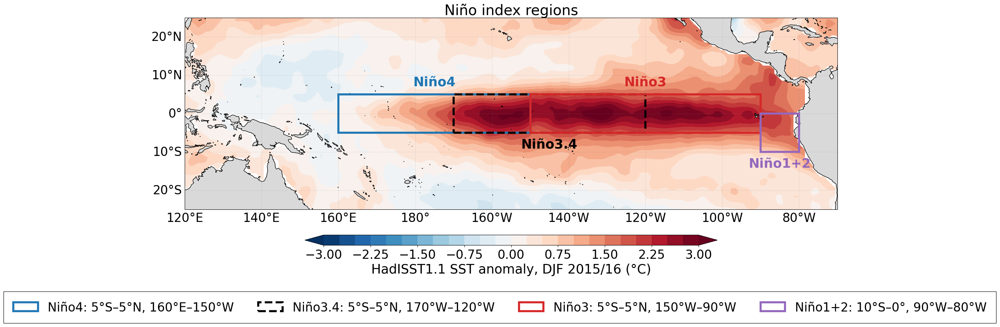

In [7]:
# ---- Map setup (fonts, figure type and dpi follow fontz / FIG / fig_type / fig_dpi above) ----
MAP = {
    "figsize": (24, 9),
    "extent": (120, 290, -25, 25),           # lon0, lon1 (0-360), lat0, lat1
    "background_year": 2015,                 # EVENTS year whose peak-season SST anomaly is shaded; None: plain map
    "background_levels": np.arange(-3.0, 3.01, 0.25),
    "background_cmap": "RdBu_r",
    "box_lw": 4.0,
    "label_offset": 1.5,                     # gap (degrees latitude) between a box and its name
    "lon_ticks": np.arange(120, 291, 20),     # labelled longitudes (0-360)
    "lat_ticks": np.arange(-20, 21, 10),
    "legend_gap": 0.03,                      # figure-fraction gap between the colorbar and the legend
    "regions": {                             # index -> box style and where its name goes
        "Nino4":   {"color": "tab:blue",   "ls": "-",  "label_side": "top"},
        "Nino3.4": {"color": "k",          "ls": "--", "label_side": "bottom"},
        "Nino3":   {"color": "tab:red",    "ls": "-",  "label_side": "top"},
        "Nino12":  {"color": "tab:purple", "ls": "-",  "label_side": "bottom"},
    },
}


def lon_label(lon):
    lon = lon % 360
    return "180°" if lon == 180 else (f"{lon:g}°E" if lon < 180 else f"{360 - lon:g}°W")


def lat_label(lat):
    return "0°" if lat == 0 else f"{abs(lat):g}°{'N' if lat > 0 else 'S'}"


def plot_nino_regions():
    fig, ax = plt.subplots(figsize=MAP["figsize"], subplot_kw={"projection": ccrs.PlateCarree(central_longitude=180)})
    lon0, lon1, lat0, lat1 = MAP["extent"]
    ax.set_extent([lon0, lon1, lat0, lat1], crs=ccrs.PlateCarree())

    cb = None
    year = MAP["background_year"]
    if year is not None:
        season = EVENTS[year]["peak_season"]
        anom = rc.obs_anomaly("TS", years=(year, year + 2), mode=derivation_mode, product=OBS_REFERENCE)
        field = rc.obs_target_mean(anom, season["months"])
        if bool(field.notnull().any()):
            data, lon = add_cyclic_point(field.values, coord=field["lon"].values)
            cf = ax.contourf(lon, field["lat"].values, data, levels=MAP["background_levels"],
                             cmap=MAP["background_cmap"], extend="both", transform=ccrs.PlateCarree(), zorder=0)
            cb = fig.colorbar(cf, ax=ax, orientation="horizontal", pad=0.1, shrink=0.6, aspect=40)
            cb.set_label(f"{OBS_REFERENCE} SST anomaly, {season['label']} (°C)", fontsize=FIG["label"])
            cb.ax.tick_params(labelsize=FIG["tick"])
        else:
            print(f"{season['label']} is not observed yet; plain map")

    ax.add_feature(cfeature.LAND, facecolor="0.85", zorder=2)
    ax.coastlines(lw=1.0, zorder=3)
    for name, style in MAP["regions"].items():
        x0, x1, y0, y1 = rc.NINO_REGIONS[name]
        bounds = f"{lat_label(y0)}–{lat_label(y1)}, {lon_label(x0)}–{lon_label(x1)}"
        ax.add_patch(mpatches.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=style["color"],
                                        ls=style["ls"], lw=MAP["box_lw"], transform=ccrs.PlateCarree(), zorder=4,
                                        label=f"{INDEX_LABELS.get(name, name)}: {bounds}"))
        top = style["label_side"] == "top"
        ax.text((x0 + x1) / 2, y1 + MAP["label_offset"] if top else y0 - MAP["label_offset"], INDEX_LABELS.get(name, name).split(" ")[0],
                ha="center", va="bottom" if top else "top", color=style["color"], fontsize=FIG["label"],
                fontweight="bold", transform=ccrs.PlateCarree(), zorder=5)

    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True, lw=0.6, color="0.5", alpha=0.5, ls=":")
    gl.top_labels = gl.right_labels = False
    gl.xlocator = mticker.FixedLocator([(lon + 180) % 360 - 180 for lon in MAP["lon_ticks"]])
    gl.ylocator = mticker.FixedLocator(MAP["lat_ticks"])
    gl.xlabel_style = gl.ylabel_style = {"size": FIG["tick"]}
    ax.set_title("Niño index regions", fontsize=FIG["suptitle"])

    # Legend just below the lowest element (colorbar with its label, or the map)
    fig.canvas.draw()
    lowest = (cb.ax if cb is not None else ax).get_tightbbox().transformed(fig.transFigure.inverted()).y0
    handles, labels = ax.get_legend_handles_labels()
    legend = fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, lowest - MAP["legend_gap"]),
                        ncol=FIG["legend_ncol"], fontsize=FIG["legend"], **FIG["legend_box"])
    legend.get_frame().set_linewidth(1.2)
    return fig


fig = plot_nino_regions()
save_fig(fig, "rtenso2026", "nino_regions")
plt.show()

### Peak-season summary

Ensemble-mean and member range of each index over the peak season, with the peak month of the ensemble mean.

In [8]:
rows = []
for year, event in EVENTS.items():
    months = event["peak_season"]["months"]
    for index in INDICES:
        obs_index = obs_indices[(year, OBS_REFERENCE)][index]
        obs_peak_season = float(rc.obs_target_mean(obs_index, months))   # NaN until the season is observed
        obs_2yr = obs_index.sel(time=slice(f"{year}-01", f"{year + 1}-12")).dropna("time")
        obs_peak = obs_2yr.isel(time=int(obs_2yr.argmax("time")))
        for (fc_year, case, init), ds in fc_index.items():
            if fc_year != year:
                continue
            season = rc.target_mean(ds[index], months)
            if season is None:
                continue
            ens = ds[index].mean("member")
            peak = ens.isel(lead=int(ens.argmax("lead")))
            lead_to_season = [i for i, t in enumerate(ds["time"].values) if (t.year, t.month) == months[1]][0]
            rows.append({
                "year": year, "index": index, "case": case, "start": MONTH_NAMES[init],
                "season": event["peak_season"]["label"], "lead_to_centre_month": lead_to_season,
                "obs_peak_season": round(obs_peak_season, 2),
                **{f"obs_peak_season_{p}": round(float(rc.obs_target_mean(obs_indices[(year, p)][index], months)), 2)
                   for p in OBS_PRODUCTS if p != OBS_REFERENCE},
                "ens_mean_peak_season": round(float(season.mean("member")), 2),
                "member_min": round(float(season.min()), 2), "member_max": round(float(season.max()), 2),
                "error": round(float(season.mean("member")) - obs_peak_season, 2),
                "ens_peak": round(float(peak), 2), "ens_peak_month": f"{peak['time'].item().year}-{peak['time'].item().month:02d}",
                "obs_peak_to_date": round(float(obs_peak), 2),
                "obs_peak_month": f"{obs_peak['time'].item().year}-{obs_peak['time'].item().month:02d}",
            })
summary = pd.DataFrame(rows)
summary_file = OUTDIR / "RTENSO2026_case_Nino_peak_summary.csv"
summary.to_csv(summary_file, index=False)
print(summary_file)
summary[summary["index"] == "Nino3.4"]

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/data/RTENSO2026_case_Nino_peak_summary.csv


,year,index,case,start,season,lead_to_centre_month,obs_peak_season,obs_peak_season_ERSSTv5,obs_peak_season_ESA_CCI_SST,obs_peak_season_OISSTv2.1,ens_mean_peak_season,member_min,member_max,error,ens_peak,ens_peak_month,obs_peak_to_date,obs_peak_month
0,2015,Nino3.4,Reanalysis-CLIM,Feb,DJF 2015/16,11,2.42,2.48,2.69,2.49,1.30,-0.21,2.42,-1.13,1.33,2016-02,2.59,2015-11
1,2015,Nino3.4,Reanalysis-CLIM,May,DJF 2015/16,8,2.42,2.48,2.69,2.49,3.13,1.96,3.87,0.71,3.24,2016-01,2.59,2015-11
2,2015,Nino3.4,Reanalysis-CLIM,Aug,DJF 2015/16,5,2.42,2.48,2.69,2.49,2.48,2.00,3.17,0.05,2.82,2015-09,2.59,2015-11
3,2015,Nino3.4,Reanalysis-CLIM,Nov,DJF 2015/16,2,2.42,2.48,2.69,2.49,2.47,2.12,2.74,0.05,2.84,2015-12,2.59,2015-11
4,2015,Nino3.4,Reanalysis-OBS,Feb,DJF 2015/16,11,2.42,2.48,2.69,2.49,1.47,-0.06,2.71,-0.96,1.55,2015-12,2.59,2015-11
5,2015,Nino3.4,Reanalysis-OBS,May,DJF 2015/16,8,2.42,2.48,2.69,2.49,3.09,2.22,3.64,0.67,3.22,2015-12,2.59,2015-11
6,2015,Nino3.4,Reanalysis-OBS,Aug,DJF 2015/16,5,2.42,2.48,2.69,2.49,2.67,1.59,3.51,0.24,2.92,2015-10,2.59,2015-11
7,2015,Nino3.4,Reanalysis-OBS,Nov,DJF 2015/16,2,2.42,2.48,2.69,2.49,2.51,1.89,2.90,0.08,2.82,2015-12,2.59,2015-11
8,2015,Nino3.4,Reanalysis-NSIDC,Feb,DJF 2015/16,11,2.42,2.48,2.69,2.49,1.19,-0.08,2.47,-1.24,1.23,2017-01,2.59,2015-11
9,2015,Nino3.4,Reanalysis-NSIDC,May,DJF 2015/16,8,2.42,2.48,2.69,2.49,2.91,1.60,3.59,0.48,3.04,2015-12,2.59,2015-11


### Nino3.4 ensemble-mean error and spread by target month

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_error_spread_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_error_spread_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_error_spread_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2015_nino3_4_error_spread_init11.png


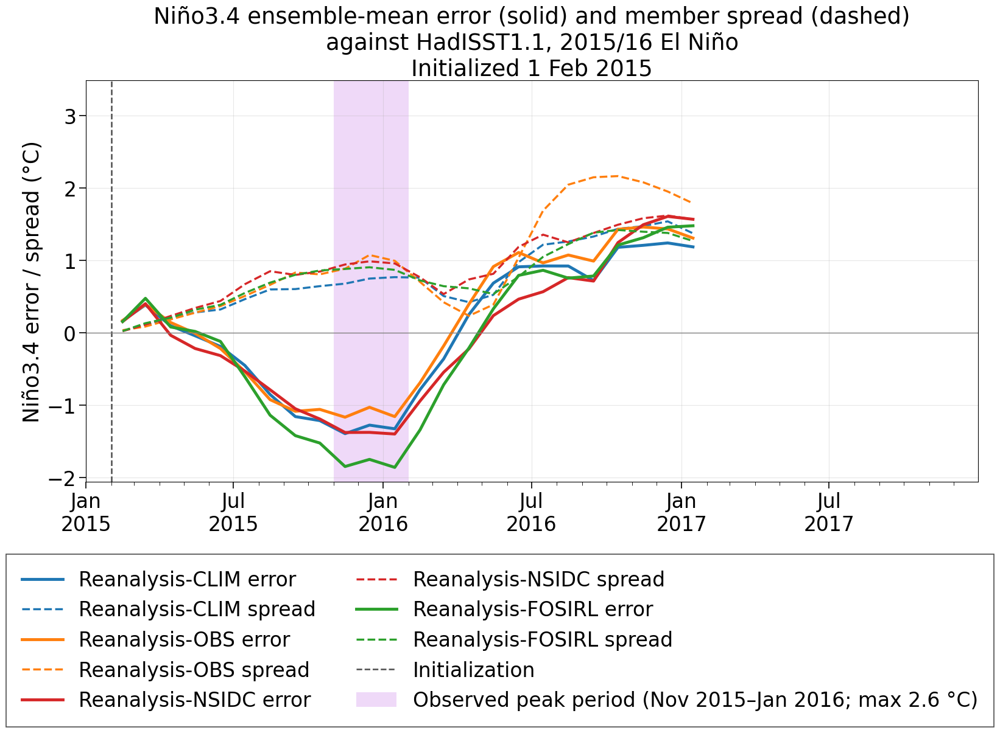

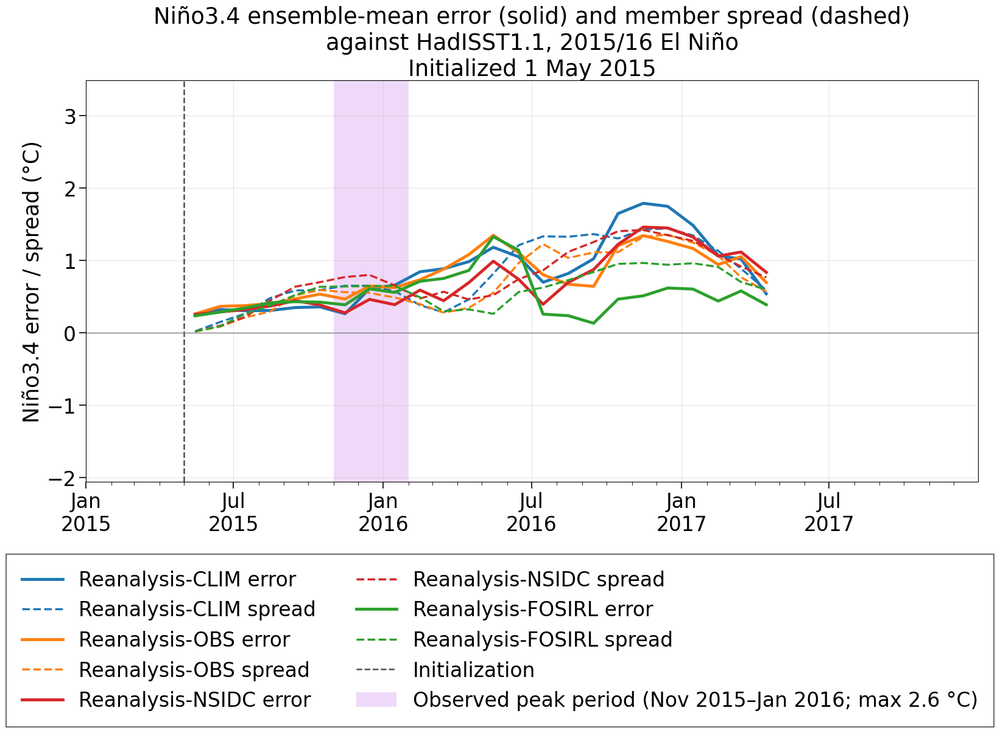

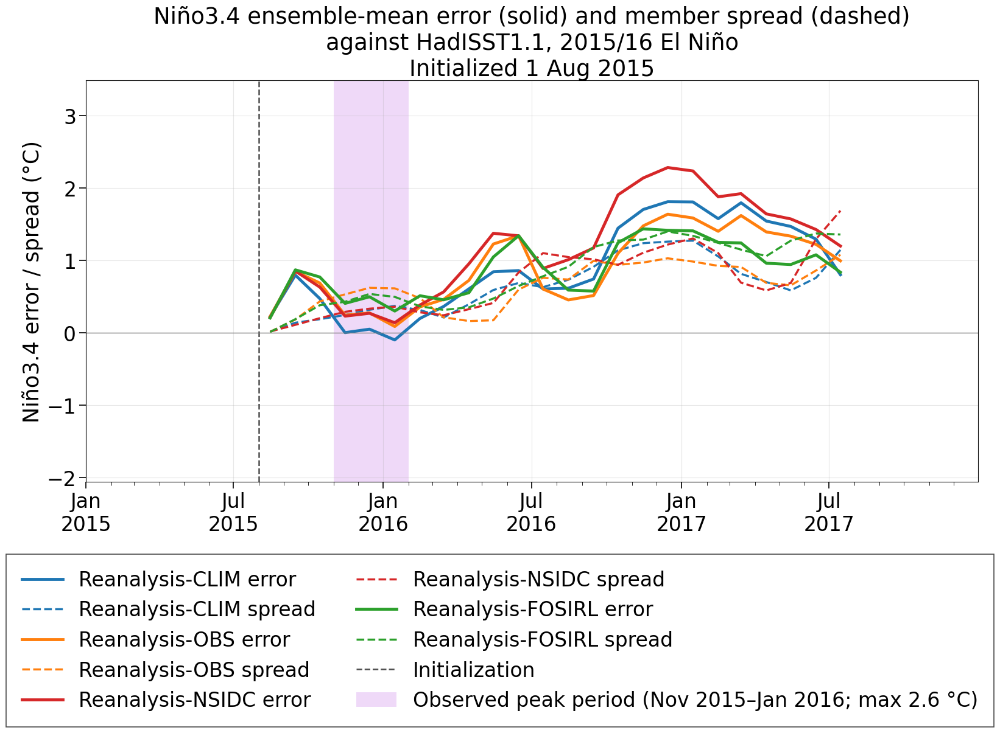

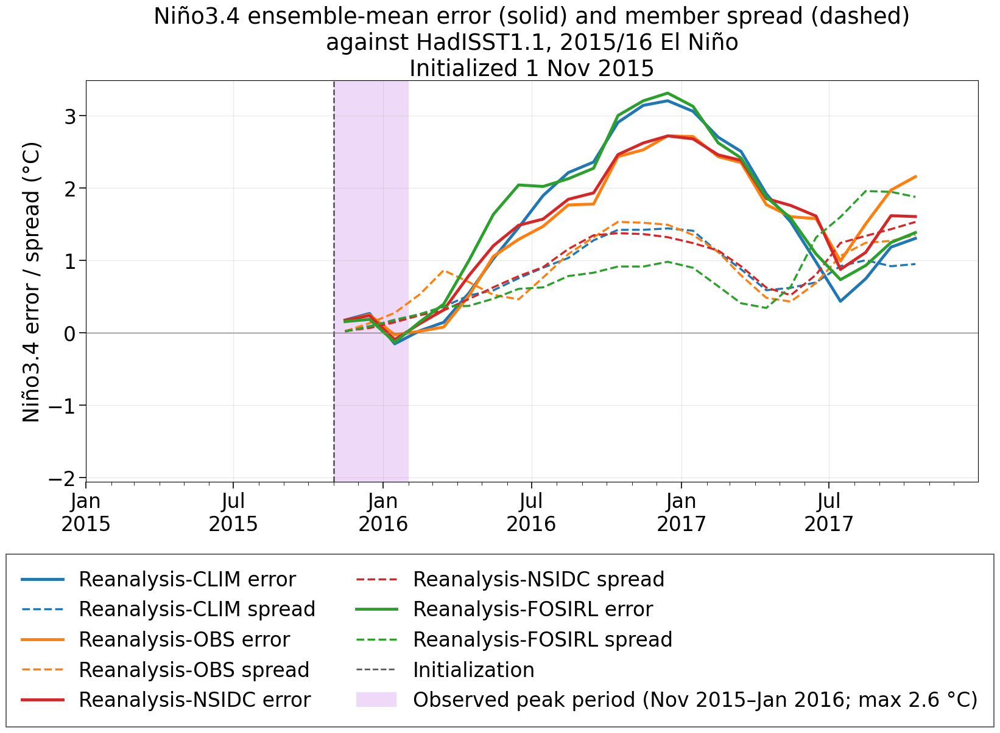

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_error_spread_init02.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_error_spread_init05.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_error_spread_init08.png


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-rtenso2026/1_enso_plume/figures/fig_rtenso2026_enso_plume_y2026_nino3_4_error_spread_init11.png


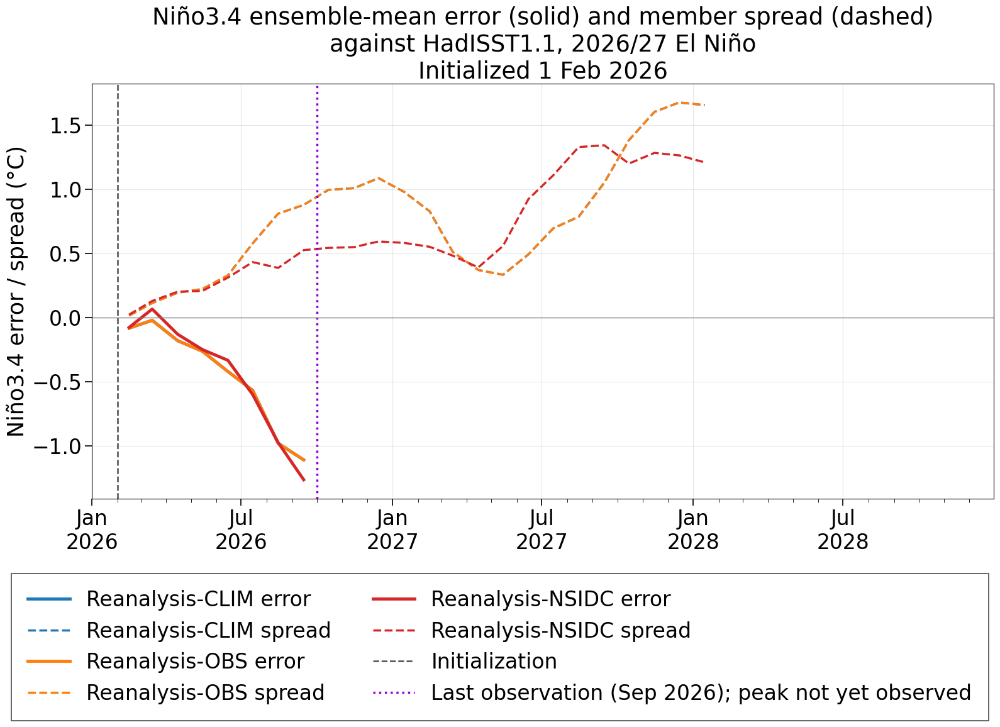

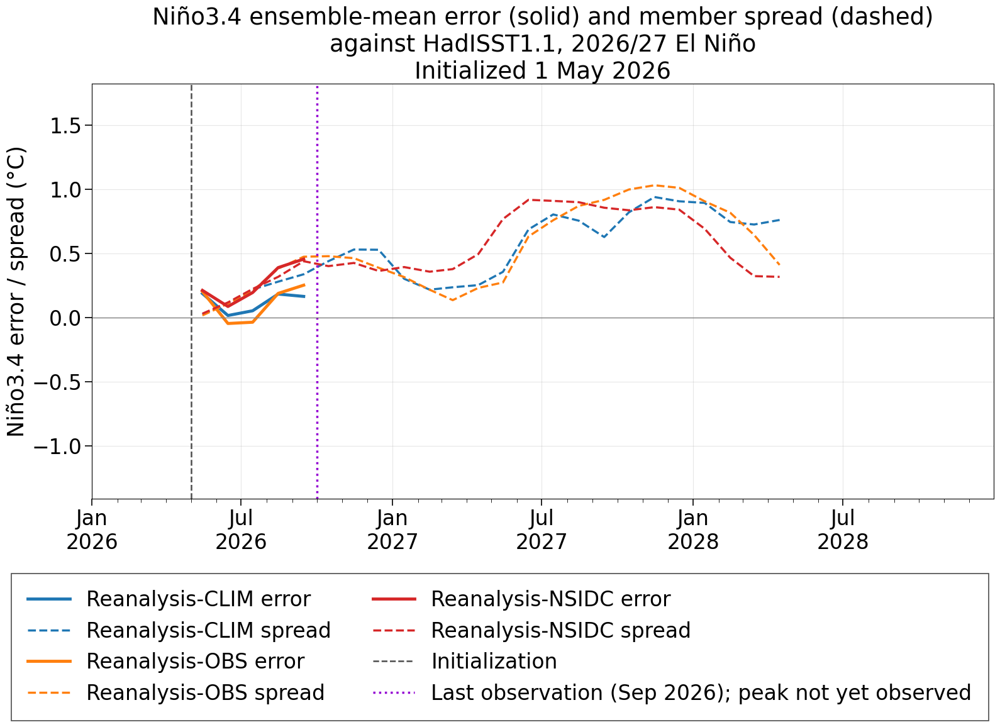

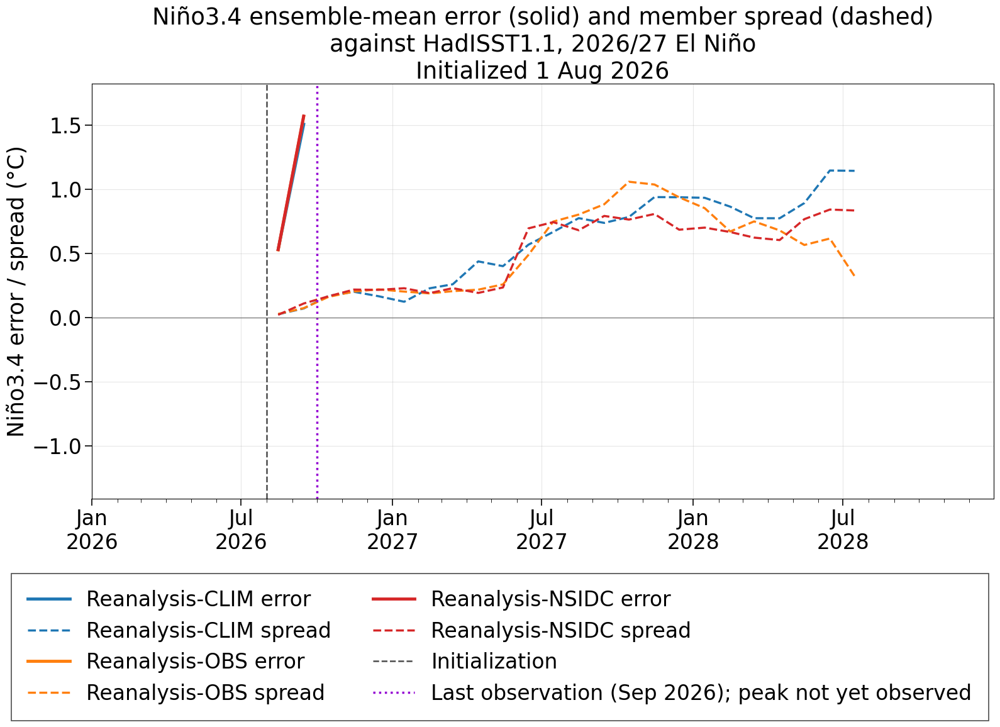

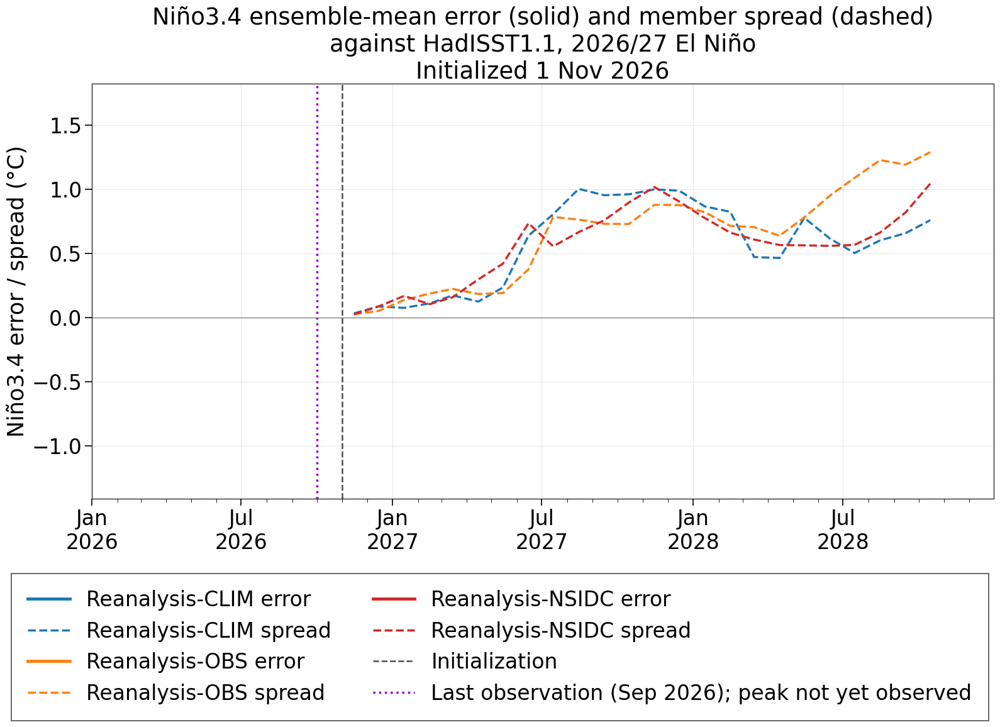

In [9]:
for year, event in EVENTS.items():
    obs = obs_indices[(year, OBS_REFERENCE)]["Nino3.4"]
    peak = observed_peak("Nino3.4", year)
    panels = init_axes(year, figsize=FIG["error_figsize"])
    for _, ax, init in panels:
        for case in CASES:
            ds = fc_index.get((year, case, init))
            if ds is None:
                continue
            fc = ds["Nino3.4"]
            error = fc.mean("member") - rc.match_obs(fc, obs)   # NaN past the last observation
            x, color = to_datetime(ds["time"].values), CASES[case]["color"]
            ax.plot(x, error, color=color, lw=FIG["ens_lw"], label=f"{case} error")
            ax.plot(x, fc.std("member"), color=color, lw=FIG["ens_lw"] * 0.7, ls="--", label=f"{case} spread")
        mark_start_and_peak(ax, year, init, peak)
        format_axis(ax, year, "Niño3.4 error / spread (°C)" if ax.get_subplotspec().is_first_col() else None,
                    init=init if SEPARATE_INITS else None)
    finish_figures(panels, year, f"Niño3.4 ensemble-mean error (solid) and member spread (dashed)\n"
                   f"against {OBS_REFERENCE}, {event['label']}",
                   "rtenso2026", "enso_plume", f"y{year}", "Nino3.4", "error_spread")
